# Moneyball EDA: Feature Exploration & Era Analysis

**Competition:** SCTPDSAI-M3-DS2F Coaching — MoneyBall Analytics
**Goal:** Understand the data, visualise feature distributions across eras, and identify normalisation strategies

## Baseball Eras (defined in the dataset)

| Era | Column | Period | Key Characteristics |
|---|---|---|---|
| Era 1 | era_1 | ~1901-1919 | Dead Ball — low scoring, small ball |
| Era 2 | era_2 | ~1920-1941 | Live Ball — Babe Ruth, offence explodes |
| Era 3 | era_3 | ~1942-1945 | WWII — depleted rosters |
| Era 4 | era_4 | ~1946-1962 | Post-war / Integration |
| Era 5 | era_5 | ~1963-1976 | Expansion — high mound then lowered (1969) |
| Era 6 | era_6 | ~1977-1993 | Free Agency — DH, artificial turf |
| Era 7 | era_7 | ~1994-2005 | Steroid Era — offensive explosion |
| Era 8 | era_8 | ~2006-2016 | Modern / Analytics — testing, three true outcomes |

The dataset also includes `decade_1910` through `decade_2010` columns and `mlb_rpg` (league average runs per game per year).


## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
sns.set_style('whitegrid')

DATA_DIR = "."

train = pd.read_csv(f"{DATA_DIR}/data_year_team_franchise.csv")
test = pd.read_csv(f"{DATA_DIR}/predict_year_team_franchise.csv")

print(f"Train: {train.shape} — Years {train['yearID'].min()}-{train['yearID'].max()}")
print(f"Test:  {test.shape} — Years {test['yearID'].min()}-{test['yearID'].max()}")
print(f"\nTarget (W) — Mean: {train['W'].mean():.1f}, Std: {train['W'].std():.1f}")

Train: (1812, 52) — Years 1904-2016
Test:  (453, 48) — Years 1892-2016

Target (W) — Mean: 79.3, Std: 13.1


## 2. Data Overview

### 2.1 Raw Column Summary


In [2]:
# Numeric stats for raw features (sorted by column order)
raw_cols = ['G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO', 'SB',
            'RA', 'ER', 'ERA', 'CG', 'SHO', 'SV', 'IPouts', 'HA', 'HRA',
            'BBA', 'SOA', 'E', 'DP', 'FP', 'mlb_rpg', 'W']

summary = train[raw_cols].describe().T
summary['missing'] = train[raw_cols].isnull().sum()
summary['dtype'] = train[raw_cols].dtypes
print(summary[['count', 'missing', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].to_string())

          count  missing         mean         std         min          25%          50%          75%          max
G        1812.0        0   159.045806    3.745286   150.00000   155.000000   162.000000   162.000000   165.000000
R        1812.0        0   700.332230  102.986154   371.00000   633.750000   700.000000   764.000000  1067.000000
AB       1812.0        0  5417.481236  170.729284  4822.00000  5302.750000  5458.000000  5539.250000  5781.000000
H        1812.0        0  1415.742826  105.994812  1044.00000  1349.750000  1414.000000  1489.000000  1783.000000
2B       1812.0        0   245.543598   45.596661   110.00000   213.000000   246.000000   280.000000   376.000000
3B       1812.0        0    44.137417   19.458443     6.00000    30.000000    39.000000    54.250000   122.000000
HR       1812.0        0   119.371965   55.666283     4.00000    82.000000   124.000000   159.000000   264.000000
BB       1812.0        0   514.248344   83.941844   282.00000   456.000000   510.500000 

In [3]:
# Train vs test year overlap
train_years = set(train['yearID'])
test_years = set(test['yearID'])
only_train = train_years - test_years
only_test = test_years - train_years
overlap = train_years & test_years

print(f"Years only in train ({len(only_train)}): {sorted(only_train)[:10]}...")
print(f"Years only in test  ({len(only_test)}):  {sorted(only_test)[:10]}...")
print(f"Overlap years:       {len(overlap)}")
print(f"\nTest extends back to {min(test_years)} — older than train ({min(train_years)})")

Years only in train (1): [1907]...
Years only in test  (3):  [1892, 1898, 1899]...
Overlap years:       107

Test extends back to 1892 — older than train (1904)


## 3. Target Distribution (W) — Sorted by Year

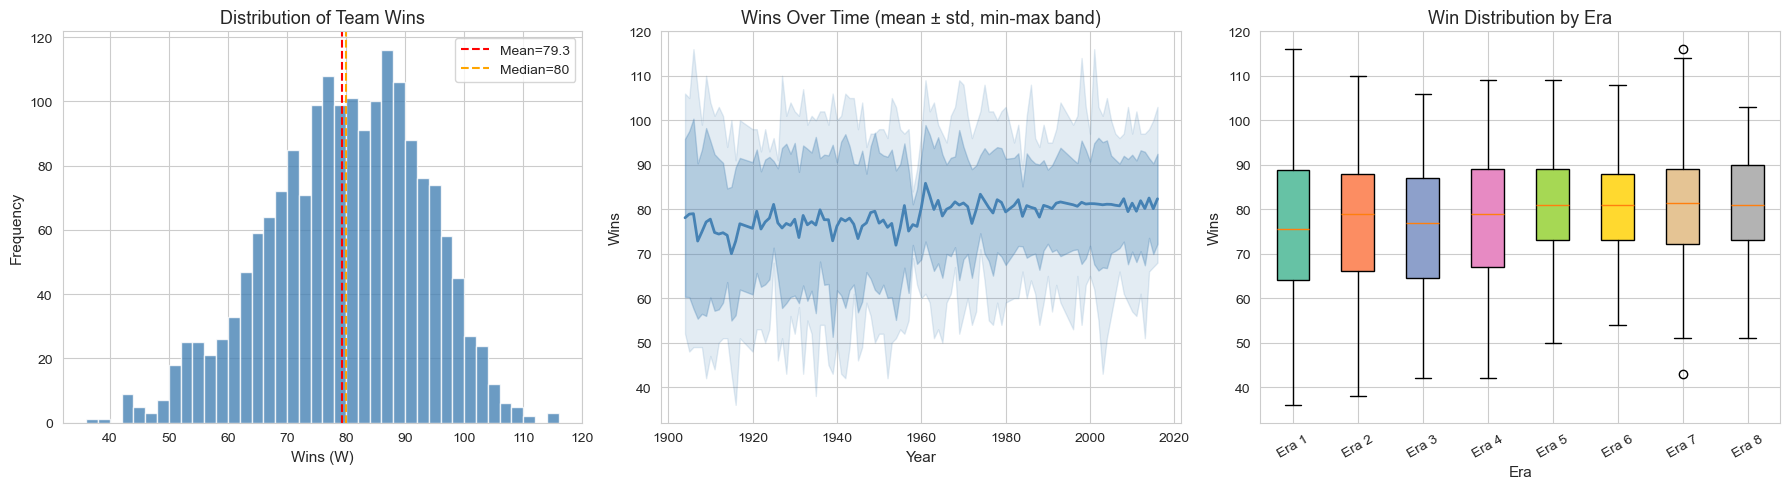

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 3a: W distribution
axes[0].hist(train['W'], bins=40, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].axvline(train['W'].mean(), color='red', ls='--', label=f"Mean={train['W'].mean():.1f}")
axes[0].axvline(train['W'].median(), color='orange', ls='--', label=f"Median={train['W'].median():.0f}")
axes[0].set_xlabel('Wins (W)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Team Wins')
axes[0].legend()

# 3b: W over time
yearly = train.groupby('yearID')['W'].agg(['mean', 'std', 'min', 'max'])
axes[1].fill_between(yearly.index, yearly['min'], yearly['max'], alpha=0.15, color='steelblue')
axes[1].fill_between(yearly.index, yearly['mean']-yearly['std'], yearly['mean']+yearly['std'],
                     alpha=0.3, color='steelblue')
axes[1].plot(yearly.index, yearly['mean'], color='steelblue', lw=2)
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Wins')
axes[1].set_title('Wins Over Time (mean ± std, min-max band)')

# 3c: W by era
era_cols = [c for c in train.columns if c.startswith('era_')]
era_map = {}
for _, row in train.iterrows():
    for ec in era_cols:
        if row[ec]:
            era_map[row.name] = ec.replace('era_', 'Era ')
            break
train['era_label'] = pd.Series(era_map)

era_order = [f'Era {i}' for i in range(1, 9)]
era_data = [train[train['era_label'] == e]['W'].values for e in era_order if e in train['era_label'].values]
era_labels = [e for e in era_order if e in train['era_label'].values]
bp = axes[2].boxplot(era_data, labels=era_labels, patch_artist=True)
colors = plt.cm.Set2(np.linspace(0, 1, len(era_labels)))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
axes[2].set_xlabel('Era')
axes[2].set_ylabel('Wins')
axes[2].set_title('Win Distribution by Era')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 4. Feature Distributions Over Time (Oldest → Newest)

### 4.1 Counting Stats: Raw Values Show Era Confounding

These plots show how raw counting stats change dramatically across eras — demonstrating why normalisation is critical.


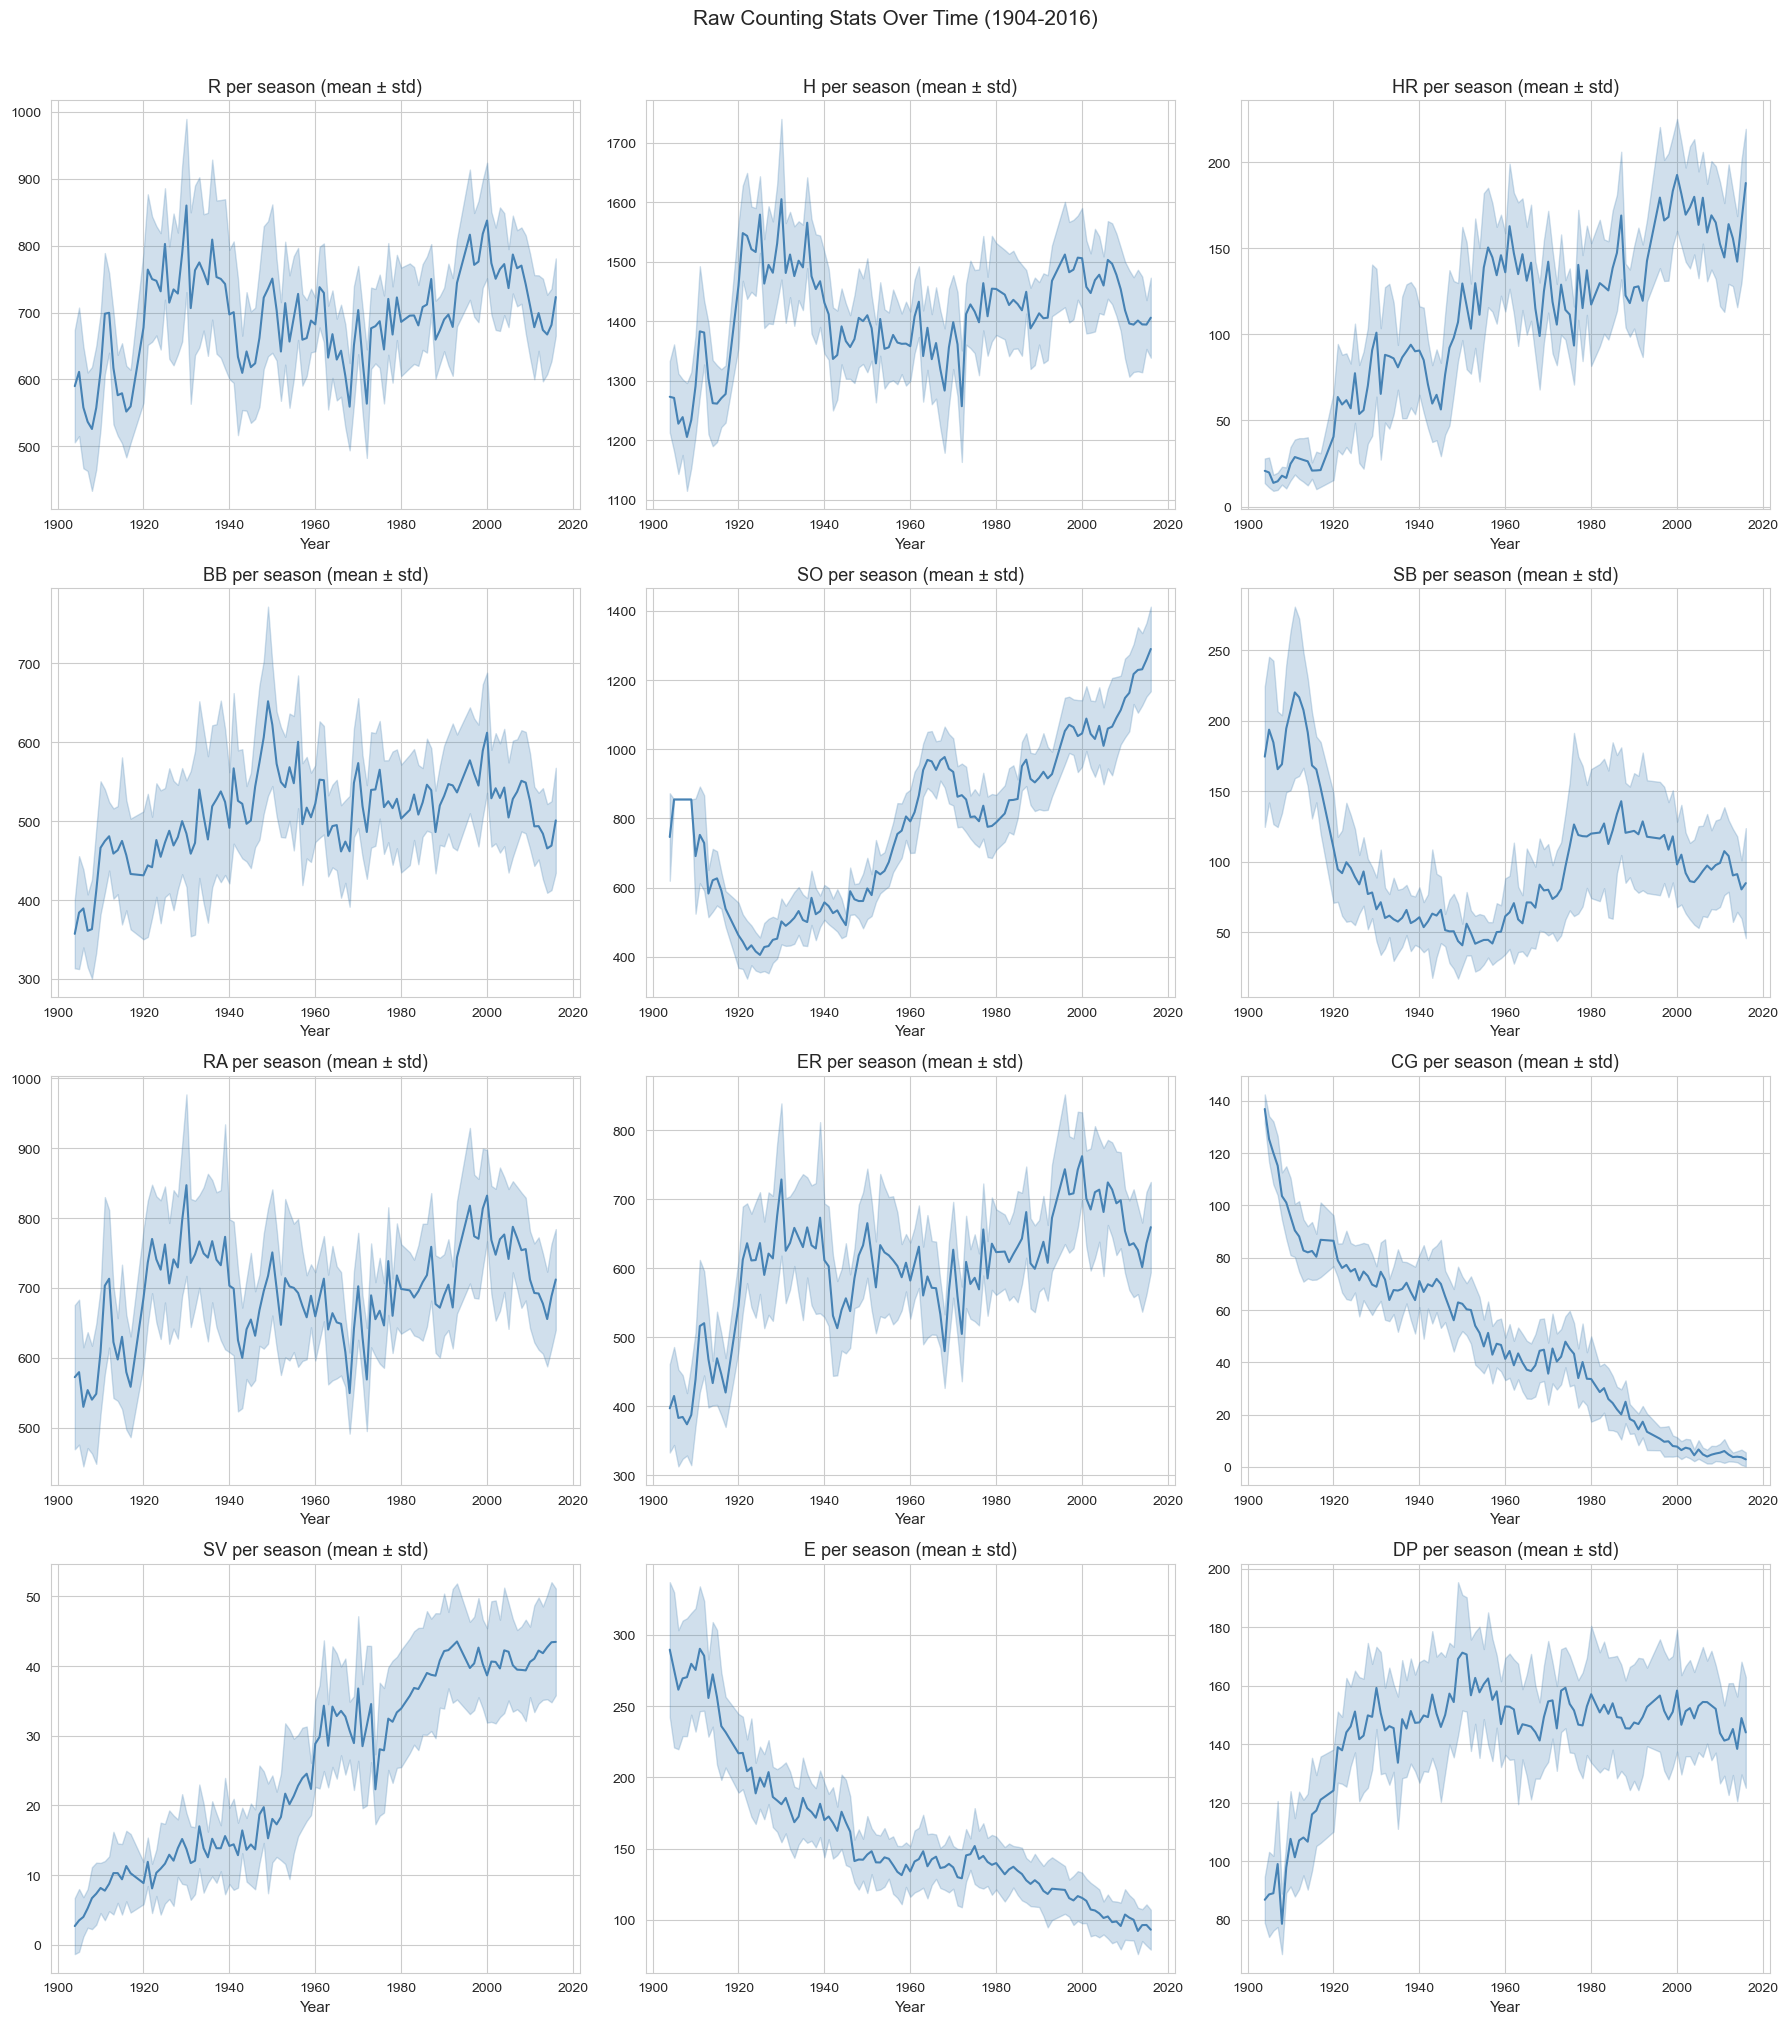

In [5]:
# Counting stats over time — 4x3 grid
counting_stats = ['R', 'H', 'HR', 'BB', 'SO', 'SB', 'RA', 'ER', 'CG', 'SV', 'E', 'DP']
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, stat in enumerate(counting_stats):
    yearly = train.groupby('yearID')[stat].agg(['mean', 'std'])
    axes[i].fill_between(yearly.index, yearly['mean']-yearly['std'], yearly['mean']+yearly['std'],
                         alpha=0.25, color='steelblue')
    axes[i].plot(yearly.index, yearly['mean'], color='steelblue', lw=1.5)
    axes[i].set_title(f'{stat} per season (mean ± std)')
    axes[i].set_xlabel('Year')

plt.suptitle('Raw Counting Stats Over Time (1904-2016)', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

### Key Observations from Counting Stats
- **HR**: Near-zero before 1920, peak ~180 in steroid era (1990s-2000s)
- **SO**: Dramatic increase from ~400 (1900s) to ~1200+ (2010s) — the "three true outcomes" trend
- **SB**: Peaks in dead ball era and again in 1980s, declining in modern era
- **CG**: Complete games declined from ~100+ to near-zero — rise of bullpen specialisation
- **SV**: Zero before ~1960, reflects invention of the closer role
- **E**: Steady decline from ~300+ to ~100 — better fielding and rule changes

These trends make raw values incomparable across eras.


### 4.2 Rate Stats: More Stable Across Eras

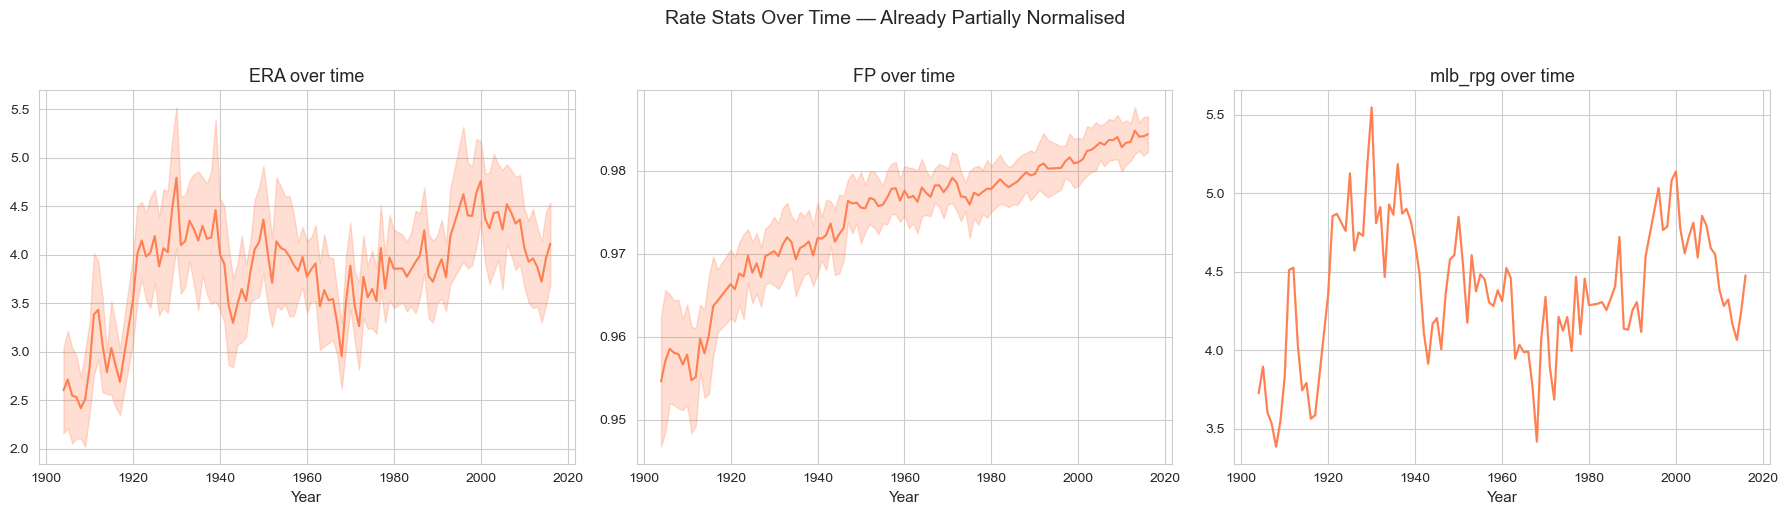

In [6]:
# Rate stats over time — these are already somewhat normalised
rate_stats = ['ERA', 'FP', 'mlb_rpg']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, stat in enumerate(rate_stats):
    yearly = train.groupby('yearID')[stat].agg(['mean', 'std'])
    axes[i].fill_between(yearly.index, yearly['mean']-yearly['std'], yearly['mean']+yearly['std'],
                         alpha=0.25, color='coral')
    axes[i].plot(yearly.index, yearly['mean'], color='coral', lw=1.5)
    axes[i].set_title(f'{stat} over time')
    axes[i].set_xlabel('Year')

plt.suptitle('Rate Stats Over Time — Already Partially Normalised', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Key Observations
- **ERA**: Ranges from ~2.5 (dead ball) to ~4.5 (steroid era) — significant era variation
- **FP (fielding %)**: Monotonic improvement from 0.94 to 0.985 — equipment and training advances
- **mlb_rpg**: League-wide run environment — the master normalisation variable


## 5. Era Breakdown — Feature Distributions by Era

### 5.1 Offence Across Eras


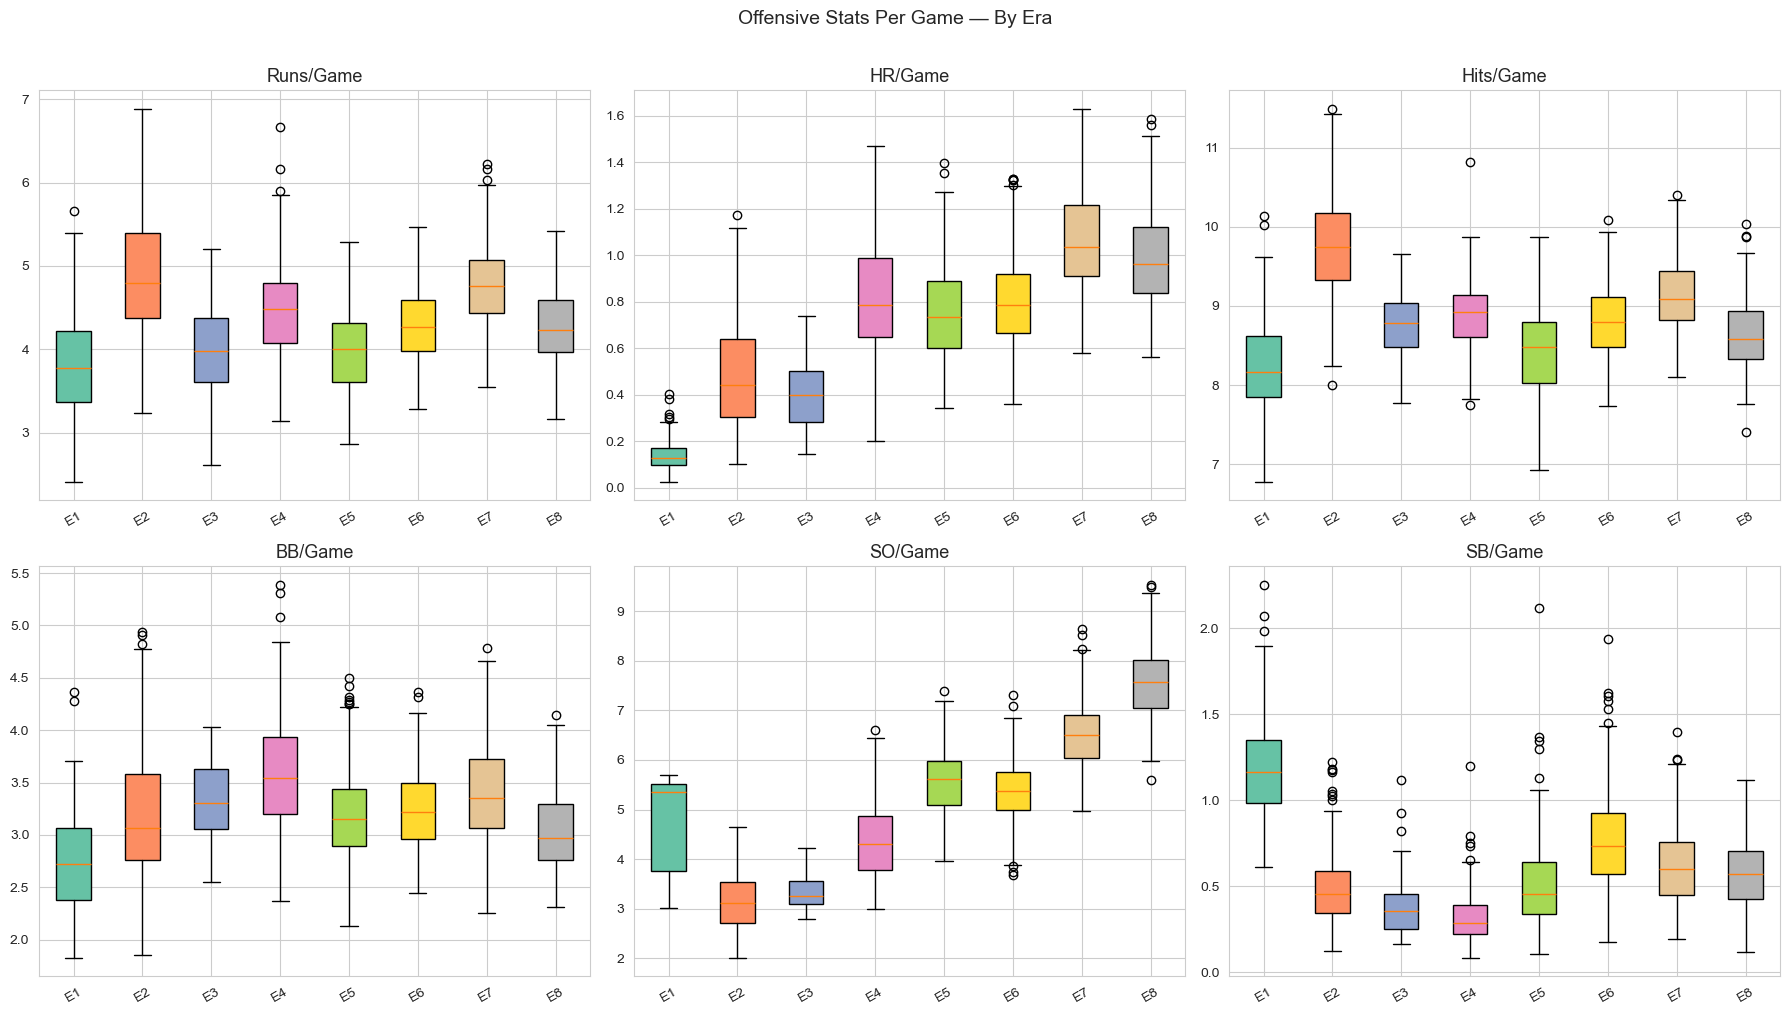

In [7]:
# Create era label if not done
if 'era_label' not in train.columns:
    era_cols = [c for c in train.columns if c.startswith('era_')]
    era_map = {}
    for _, row in train.iterrows():
        for ec in era_cols:
            if row[ec]:
                era_map[row.name] = ec.replace('era_', 'Era ')
                break
    train['era_label'] = pd.Series(era_map)

# Compute key rates for each team-season
train['R_pg'] = train['R'] / train['G']
train['HR_pg'] = train['HR'] / train['G']
train['SO_pg'] = train['SO'] / train['G']
train['BB_pg'] = train['BB'] / train['G']
train['SB_pg'] = train['SB'] / train['G']
train['H_pg'] = train['H'] / train['G']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
offence_pg = ['R_pg', 'HR_pg', 'H_pg', 'BB_pg', 'SO_pg', 'SB_pg']
titles = ['Runs/Game', 'HR/Game', 'Hits/Game', 'BB/Game', 'SO/Game', 'SB/Game']
era_order = sorted(train['era_label'].dropna().unique())

for i, (stat, title) in enumerate(zip(offence_pg, titles)):
    ax = axes[i//3][i%3]
    data = [train[train['era_label']==e][stat].dropna().values for e in era_order]
    bp = ax.boxplot(data, labels=[e.replace('Era ','E') for e in era_order], patch_artist=True)
    colors = plt.cm.Set2(np.linspace(0, 1, len(era_order)))
    for patch, c in zip(bp['boxes'], colors):
        patch.set_facecolor(c)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Offensive Stats Per Game — By Era', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 5.2 Pitching Across Eras

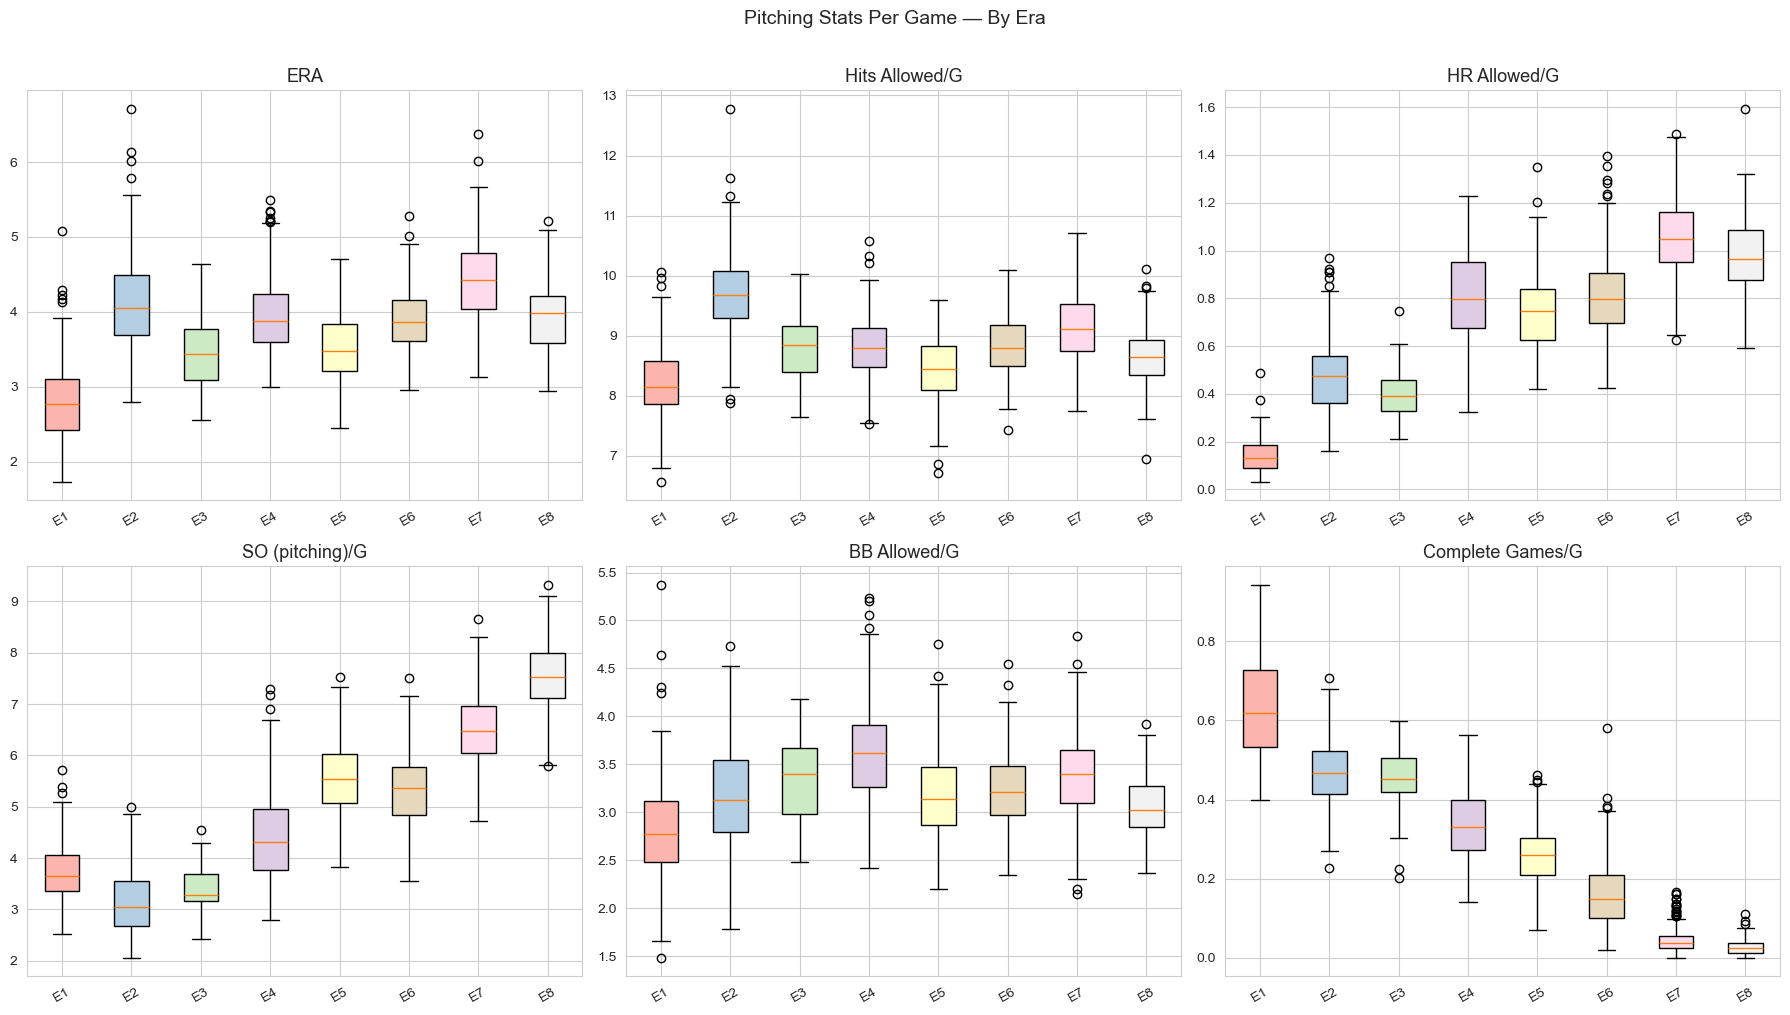

In [8]:
train['HA_pg'] = train['HA'] / train['G']
train['HRA_pg'] = train['HRA'] / train['G']
train['SOA_pg'] = train['SOA'] / train['G']
train['BBA_pg'] = train['BBA'] / train['G']
train['CG_pg'] = train['CG'] / train['G']
train['SV_pg'] = train['SV'] / train['G']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
pitch_pg = ['ERA', 'HA_pg', 'HRA_pg', 'SOA_pg', 'BBA_pg', 'CG_pg']
titles = ['ERA', 'Hits Allowed/G', 'HR Allowed/G', 'SO (pitching)/G', 'BB Allowed/G', 'Complete Games/G']

for i, (stat, title) in enumerate(zip(pitch_pg, titles)):
    ax = axes[i//3][i%3]
    data = [train[train['era_label']==e][stat].dropna().values for e in era_order]
    bp = ax.boxplot(data, labels=[e.replace('Era ','E') for e in era_order], patch_artist=True)
    colors = plt.cm.Pastel1(np.linspace(0, 1, len(era_order)))
    for patch, c in zip(bp['boxes'], colors):
        patch.set_facecolor(c)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Pitching Stats Per Game — By Era', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 5.3 All Raw Counting Stats by Era

A comprehensive view of every counting stat broken down by era — showing how dramatically the game has changed.


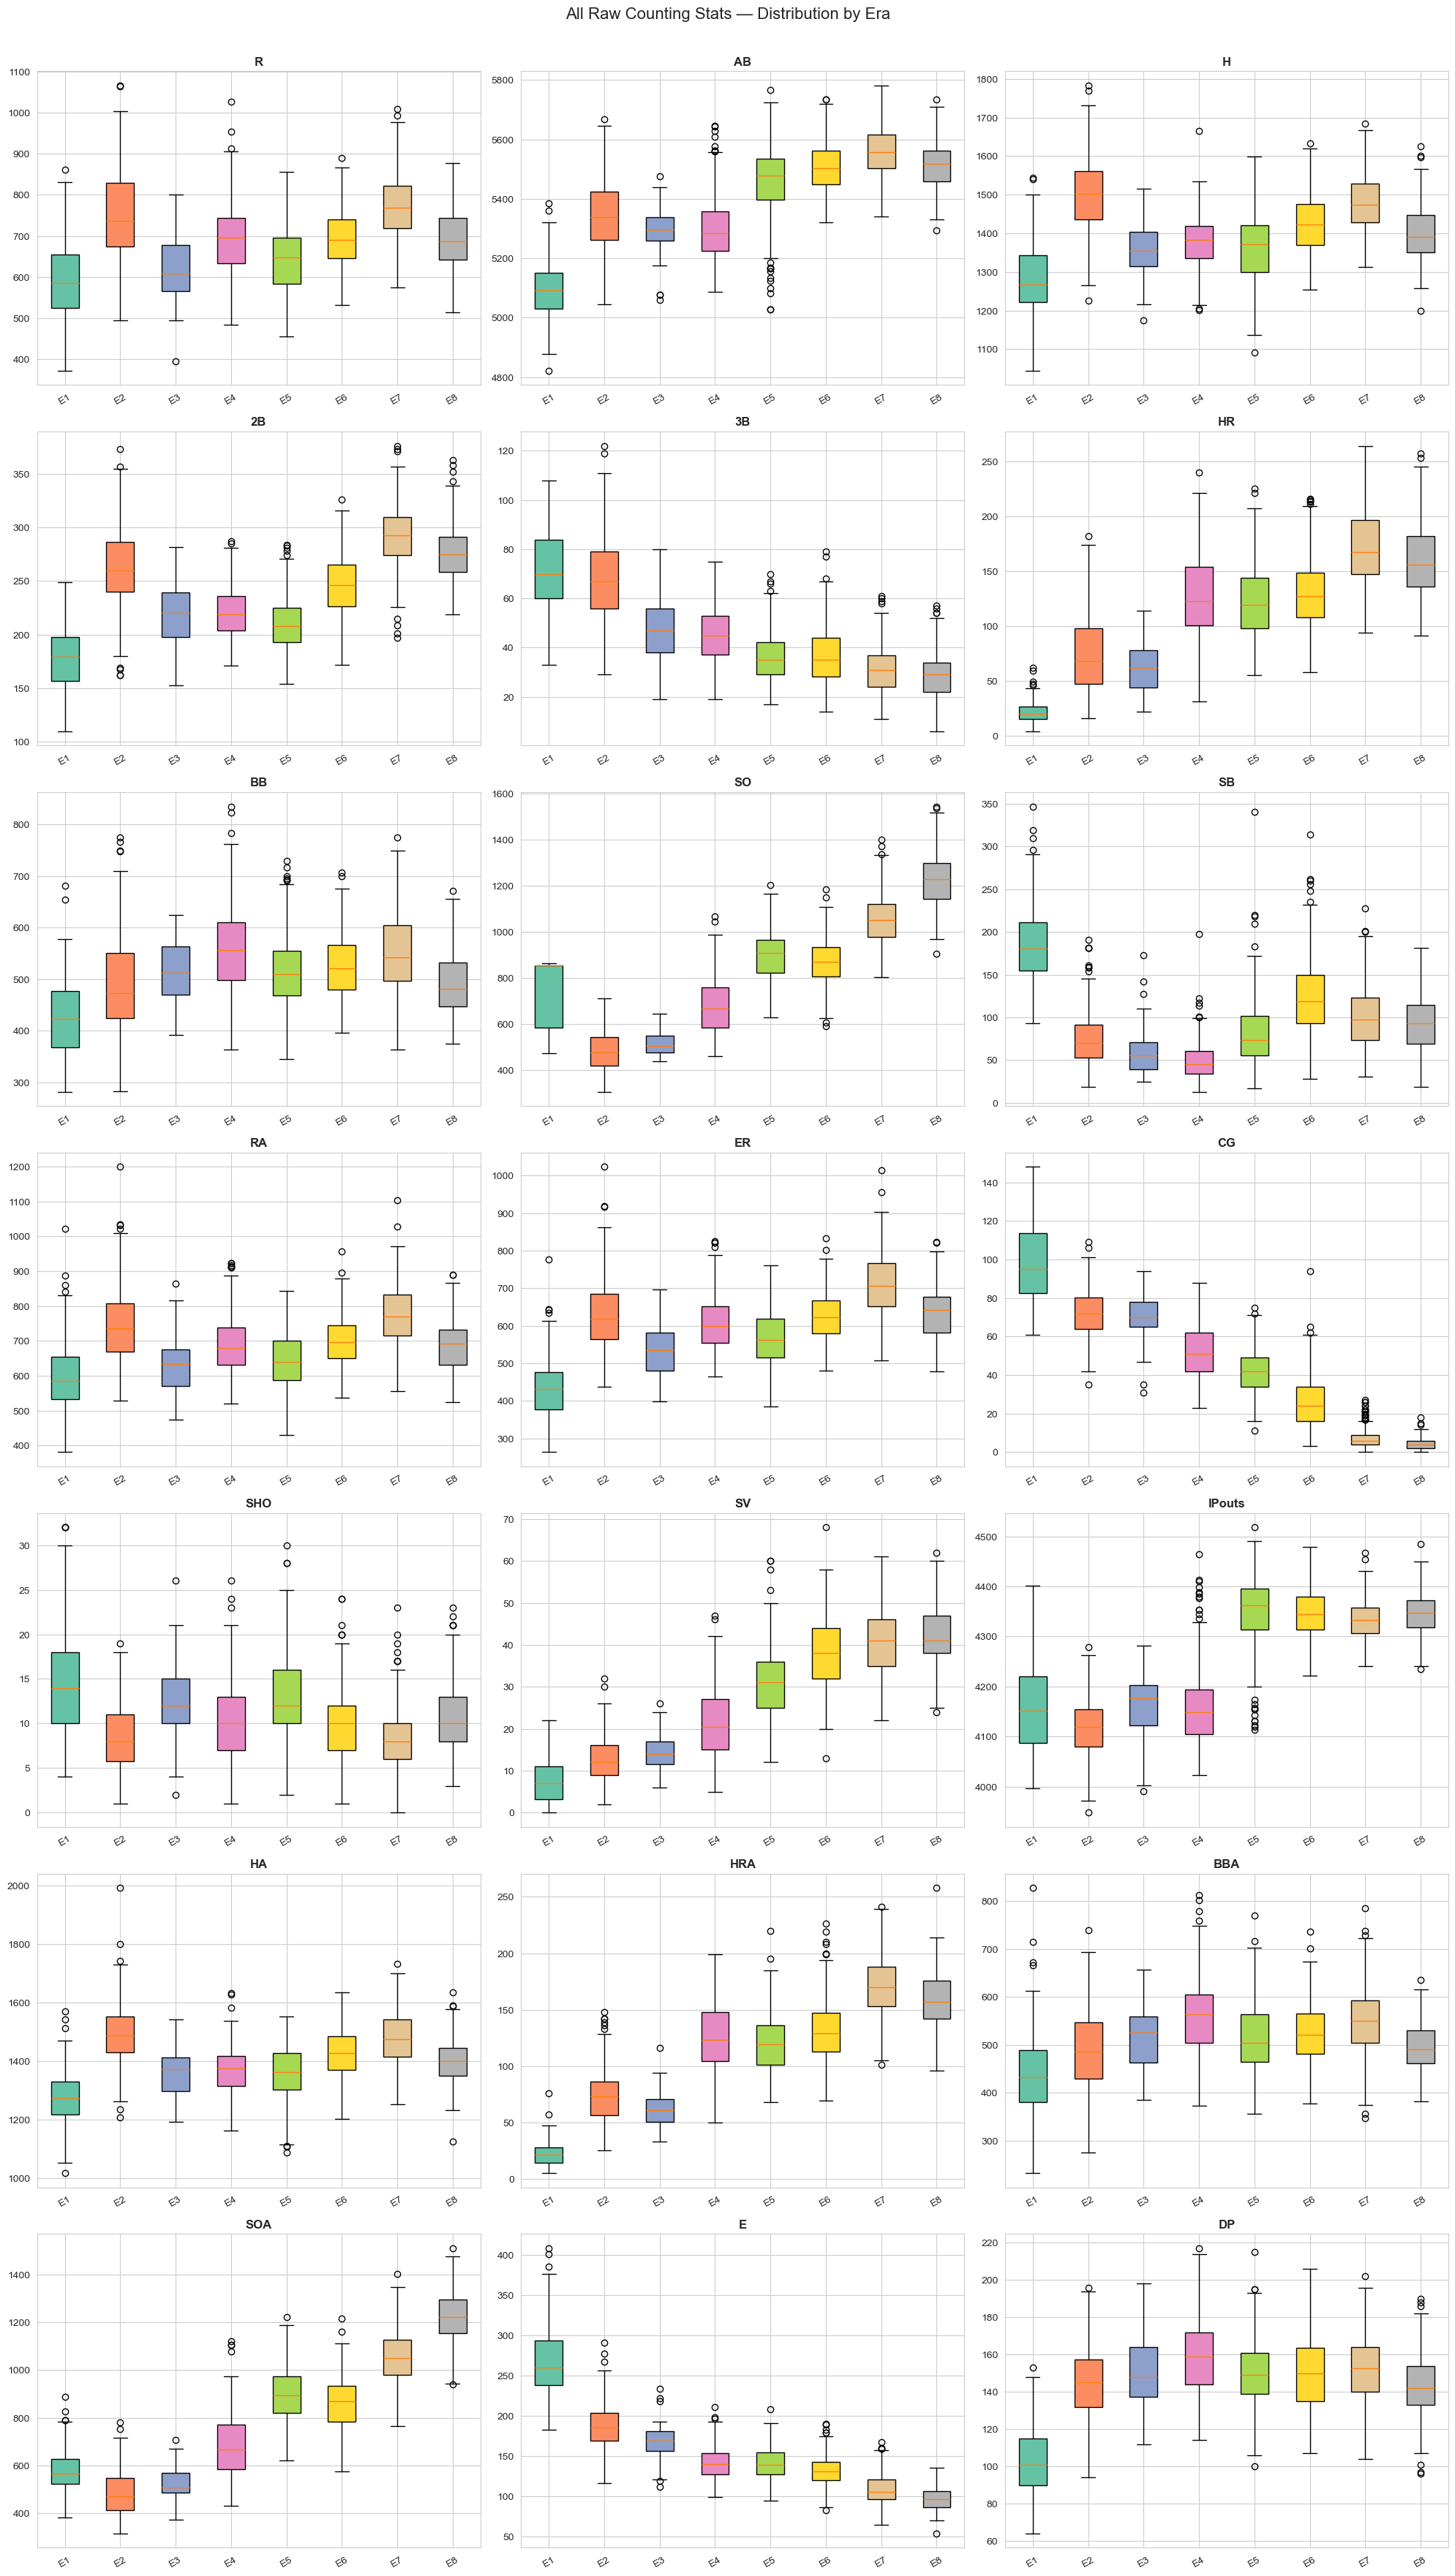

In [9]:
# All 21 raw counting stats by era — 7x3 grid
all_counting = ['R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO', 'SB',
                'RA', 'ER', 'CG', 'SHO', 'SV', 'IPouts', 'HA', 'HRA', 'BBA', 'SOA', 'E', 'DP']

fig, axes = plt.subplots(7, 3, figsize=(20, 35))
axes = axes.flatten()
era_order = sorted(train['era_label'].dropna().unique())
era_colors = plt.cm.Set2(np.linspace(0, 1, len(era_order)))

for i, stat in enumerate(all_counting):
    data = [train[train['era_label']==e][stat].dropna().values for e in era_order]
    bp = axes[i].boxplot(data, labels=[e.replace('Era ', 'E') for e in era_order], patch_artist=True)
    for patch, c in zip(bp['boxes'], era_colors):
        patch.set_facecolor(c)
    axes[i].set_title(f'{stat}', fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=30)

plt.suptitle('All Raw Counting Stats — Distribution by Era', fontsize=16, y=1.005)
plt.tight_layout()
plt.show()

### Key Takeaways — Raw Counting Stats
- **AB**: Stable ~5200-5600, slight increase with modern 162-game seasons
- **H**: Declined slightly in modern era (more strikeouts, fewer balls in play)
- **2B**: Gradual increase over time — doubles are more common in modern baseball
- **3B**: Dramatic decline — from ~70 (dead ball) to ~30 (modern). Smaller ballparks, fewer inside-the-park triples
- **HR**: Near zero in dead ball → ~200 in steroid era → stabilised ~170 in modern era
- **SO**: Most dramatic trend: ~400 → 1300+. The "three true outcomes" revolution
- **SB**: Peaked in dead ball era (~180) and again 1980s (~150), declining in analytics era
- **CG**: From 100+ to near zero — modern bullpen specialisation
- **SHO**: Declined with CG — fewer pitchers finish what they start
- **SV**: Non-existent before ~1960, peaks ~45 in modern era — invention of the closer role
- **IPouts**: Remarkably stable at ~4200-4400 (reflects season length, not strategy)
- **E**: Steady decline from 250+ to ~90 — better fielding, rule changes, artificial turf
- **DP**: Relatively stable at ~130-160, slight increase in modern era


### 5.4 All Per-Game Rates by Era

Dividing by G removes season-length confound. This is what the per-game normalisation (V5) does.


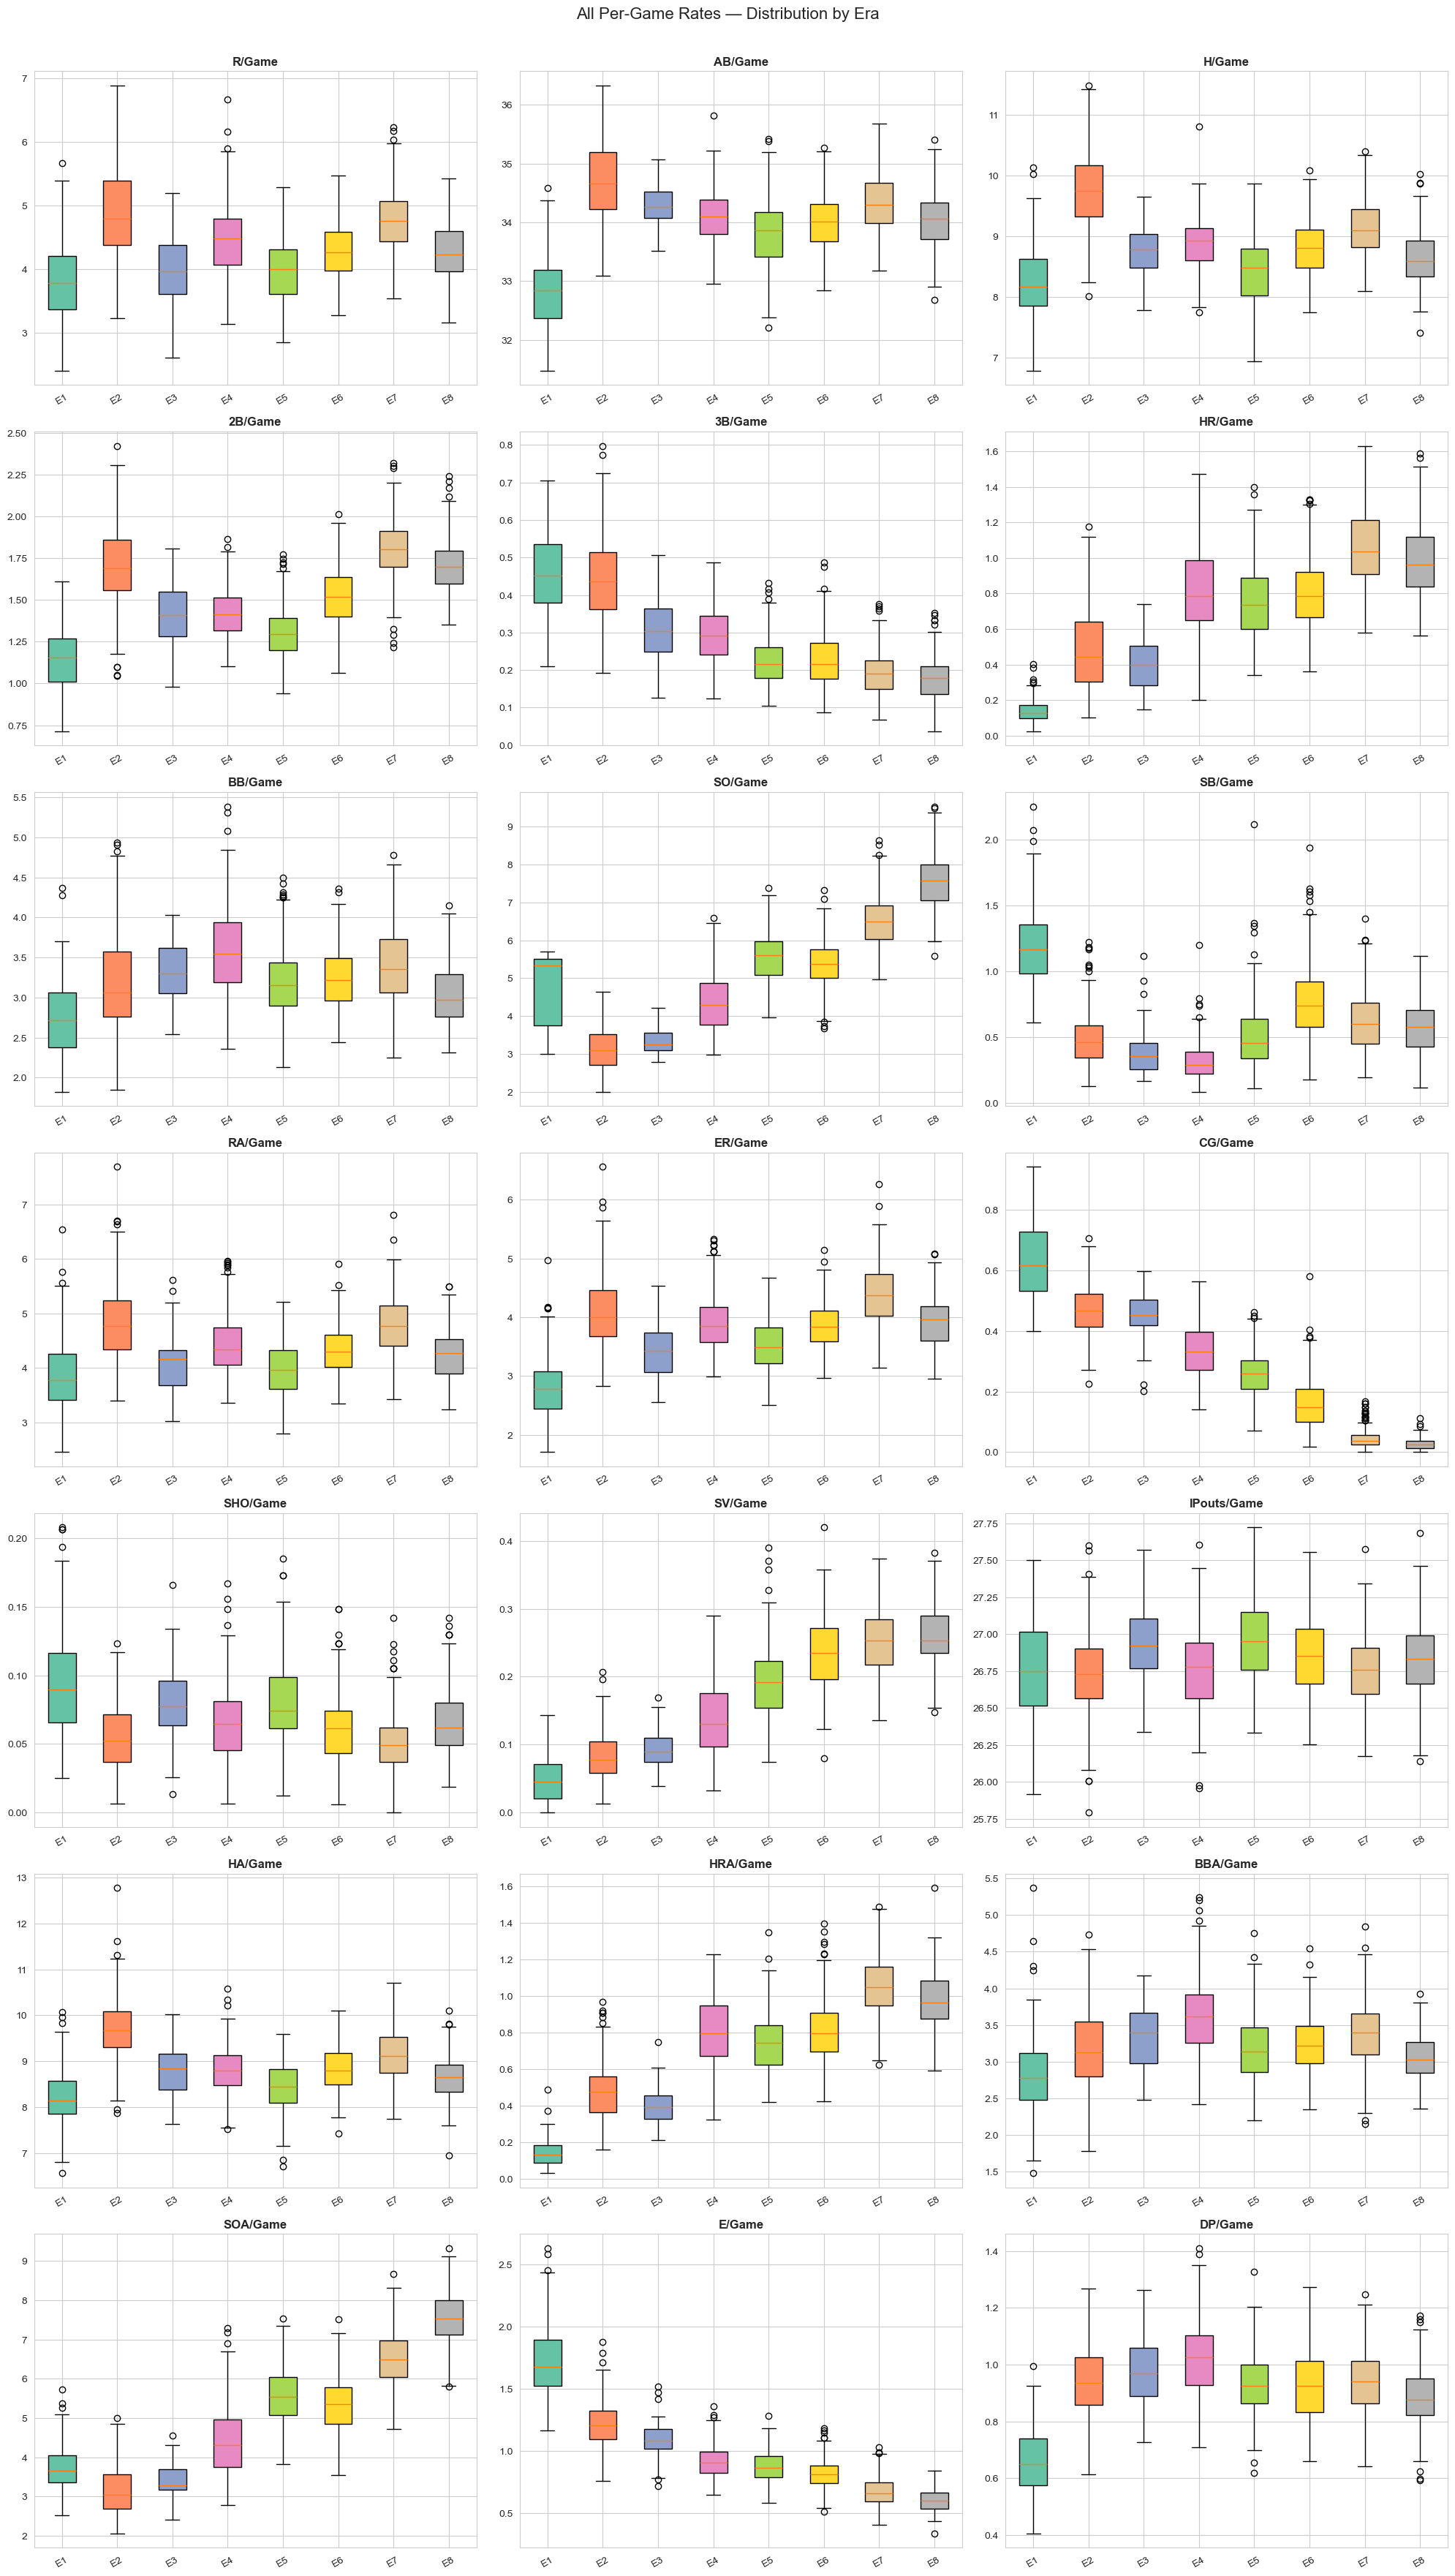

In [10]:
# Compute all per-game rates
for s in all_counting:
    col = f'{s}_pg'
    if col not in train.columns:
        train[col] = train[s] / train['G']

# Plot all 21 per-game rates by era — 7x3 grid
fig, axes = plt.subplots(7, 3, figsize=(20, 35))
axes = axes.flatten()

for i, stat in enumerate(all_counting):
    col = f'{stat}_pg'
    data = [train[train['era_label']==e][col].dropna().values for e in era_order]
    bp = axes[i].boxplot(data, labels=[e.replace('Era ', 'E') for e in era_order], patch_artist=True)
    for patch, c in zip(bp['boxes'], era_colors):
        patch.set_facecolor(c)
    axes[i].set_title(f'{stat}/Game', fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=30)

plt.suptitle('All Per-Game Rates — Distribution by Era', fontsize=16, y=1.005)
plt.tight_layout()
plt.show()

### Per-Game vs Raw: What Changes?
Per-game rates look very similar to raw stats because modern seasons are mostly 162 games. The main difference is for **earlier eras** where G varied (140-154 games), making per-game normalisation essential for fair cross-era comparison.


### 5.5 Derived Sabermetric Features by Era

These are the engineered features used in the Ridge model. Each captures a different dimension of team performance.


In [11]:
# Compute sabermetric features for EDA
G = train['G']
Rpg, RApg = train['R_pg'], train['RA'] / G
Hpg, ABpg, BBpg, SOpg = train['H_pg'], train['AB'] / G, train['BB_pg'], train['SO_pg']
HRpg, B2pg, B3pg = train['HR_pg'], train['2B'] / G, train['3B'] / G
HApg, HRApg, BBApg, SOApg = train['HA'] / G, train['HRA'] / G, train['BBA'] / G, train['SOA'] / G
IPpg = (train['IPouts'] / G) / 3
ERpg = train['ER'] / G

# Batting
train['1B_pg'] = Hpg - B2pg - B3pg - HRpg
train['TB_pg'] = train['1B_pg'] + 2*B2pg + 3*B3pg + 4*HRpg
PApg = ABpg + BBpg
train['BA']  = Hpg / (ABpg + 0.001)
train['SLG'] = train['TB_pg'] / (ABpg + 0.001)
train['OBP'] = (Hpg + BBpg) / (PApg + 0.001)
train['OPS'] = train['OBP'] + train['SLG']
train['ISO'] = train['SLG'] - train['BA']
train['wOBA'] = (0.69*BBpg + 0.89*train['1B_pg'] + 1.27*B2pg + 1.62*B3pg + 2.10*HRpg) / (PApg + 0.001)
train['BABIP'] = (Hpg - HRpg) / (ABpg - SOpg - HRpg + 0.001)
train['K_pct']  = SOpg / (PApg + 0.001)
train['BB_pct'] = BBpg / (PApg + 0.001)

# Pitching
train['WHIP'] = (BBApg + HApg) / (IPpg + 0.001)
train['FIP']  = (13*HRApg + 3*BBApg - 2*SOApg) / (IPpg + 0.001) + 3.10
train['H9']   = HApg / (IPpg + 0.001) * 9
train['SO9']  = SOApg / (IPpg + 0.001) * 9
train['BB9']  = BBApg / (IPpg + 0.001) * 9
train['SO_BB_ratio'] = SOApg / (BBApg + 0.001)

# Run differential
train['run_diff_pg'] = Rpg - RApg
R, RA = train['R'], train['RA']
train['pyth_pct'] = R**2 / (R**2 + RA**2)
rpg_total = (R + RA) / G
pexp = rpg_total ** 0.287
train['pyth_pct_pat'] = R**pexp / (R**pexp + RA**pexp)

# League-adjusted
train['ERA_plus'] = (train['mlb_rpg'] * 0.92) / (train['ERA'] + 0.001) * 100
train['OPS_plus'] = train['OPS'] / (train['mlb_rpg'] / 4.5) * 100
train['DER'] = 1 - ((HApg - HRApg) / ((train['IPouts']/G) + HApg - HRApg - SOApg + 0.001))

print("Computed all sabermetric features for EDA")

Computed all sabermetric features for EDA


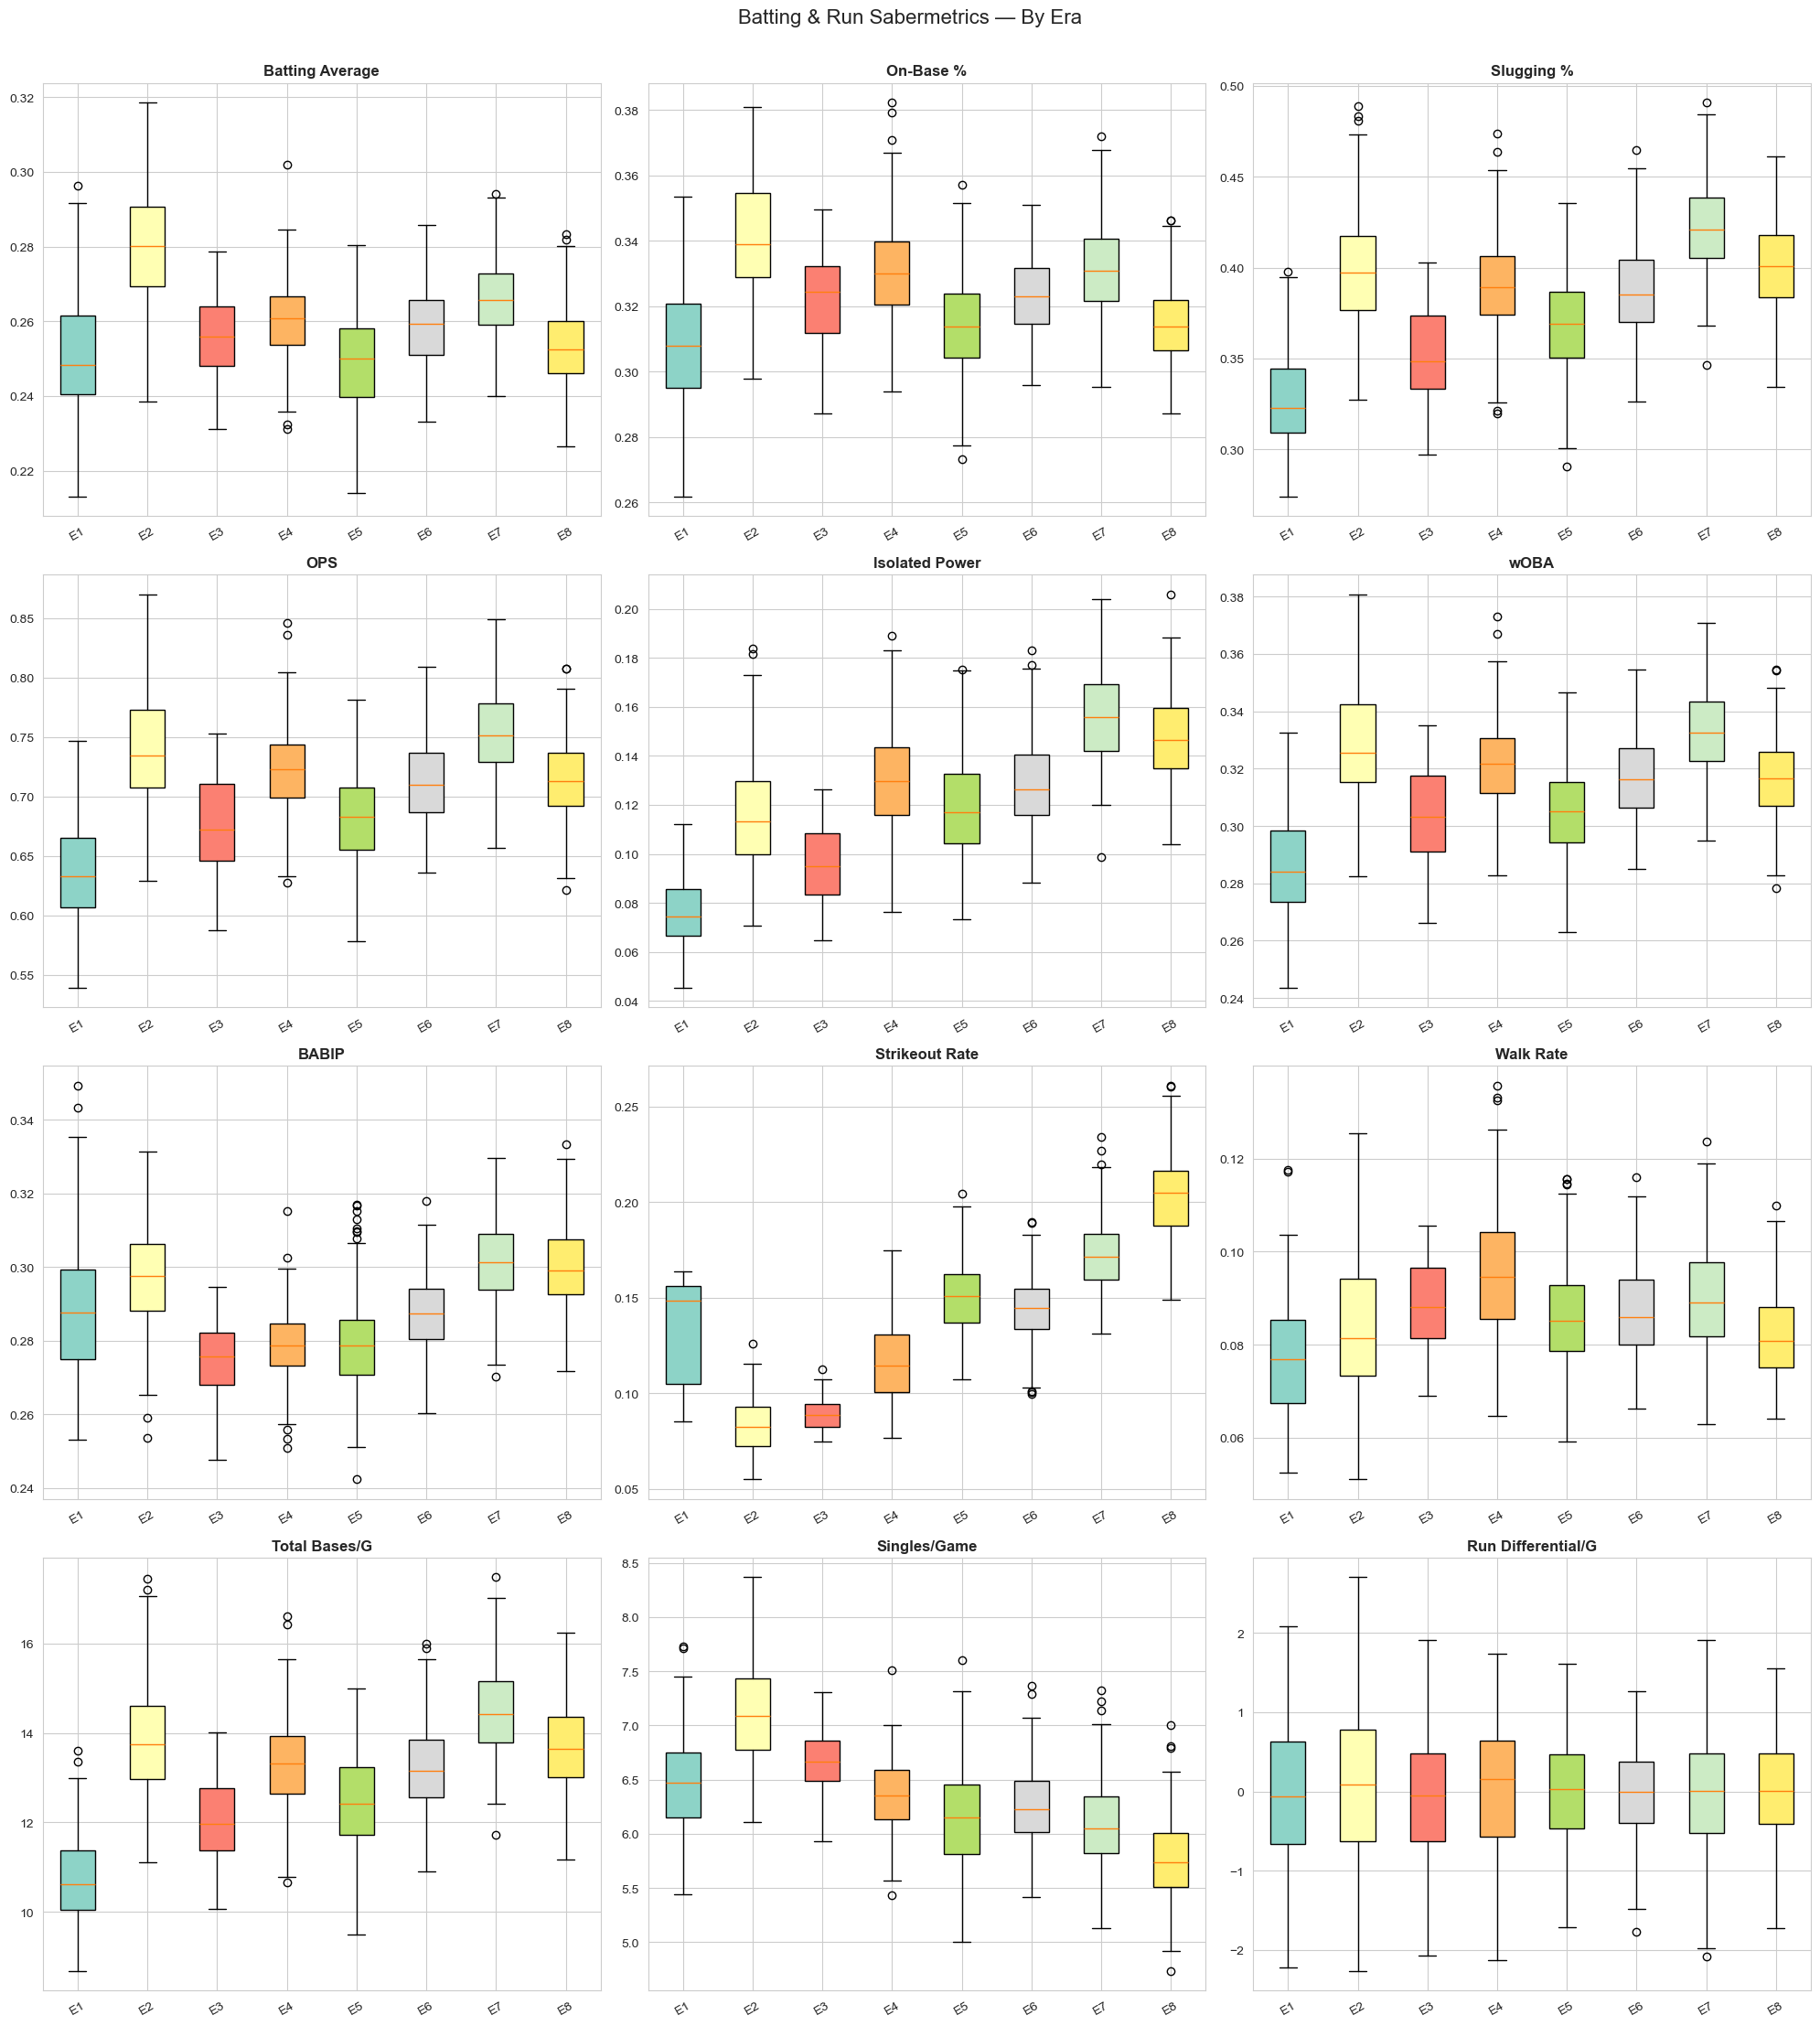

In [12]:
# Batting sabermetrics by era — 4x3 grid
batting_saber = ['BA', 'OBP', 'SLG', 'OPS', 'ISO', 'wOBA', 'BABIP', 'K_pct', 'BB_pct', 'TB_pg', '1B_pg', 'run_diff_pg']
batting_titles = ['Batting Average', 'On-Base %', 'Slugging %', 'OPS', 'Isolated Power',
                  'wOBA', 'BABIP', 'Strikeout Rate', 'Walk Rate', 'Total Bases/G',
                  'Singles/Game', 'Run Differential/G']

fig, axes = plt.subplots(4, 3, figsize=(20, 22))
axes = axes.flatten()
saber_colors = plt.cm.Set3(np.linspace(0, 1, len(era_order)))

for i, (stat, title) in enumerate(zip(batting_saber, batting_titles)):
    data = [train[train['era_label']==e][stat].dropna().values for e in era_order]
    bp = axes[i].boxplot(data, labels=[e.replace('Era ', 'E') for e in era_order], patch_artist=True)
    for patch, c in zip(bp['boxes'], saber_colors):
        patch.set_facecolor(c)
    axes[i].set_title(title, fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=30)

plt.suptitle('Batting & Run Sabermetrics — By Era', fontsize=16, y=1.005)
plt.tight_layout()
plt.show()

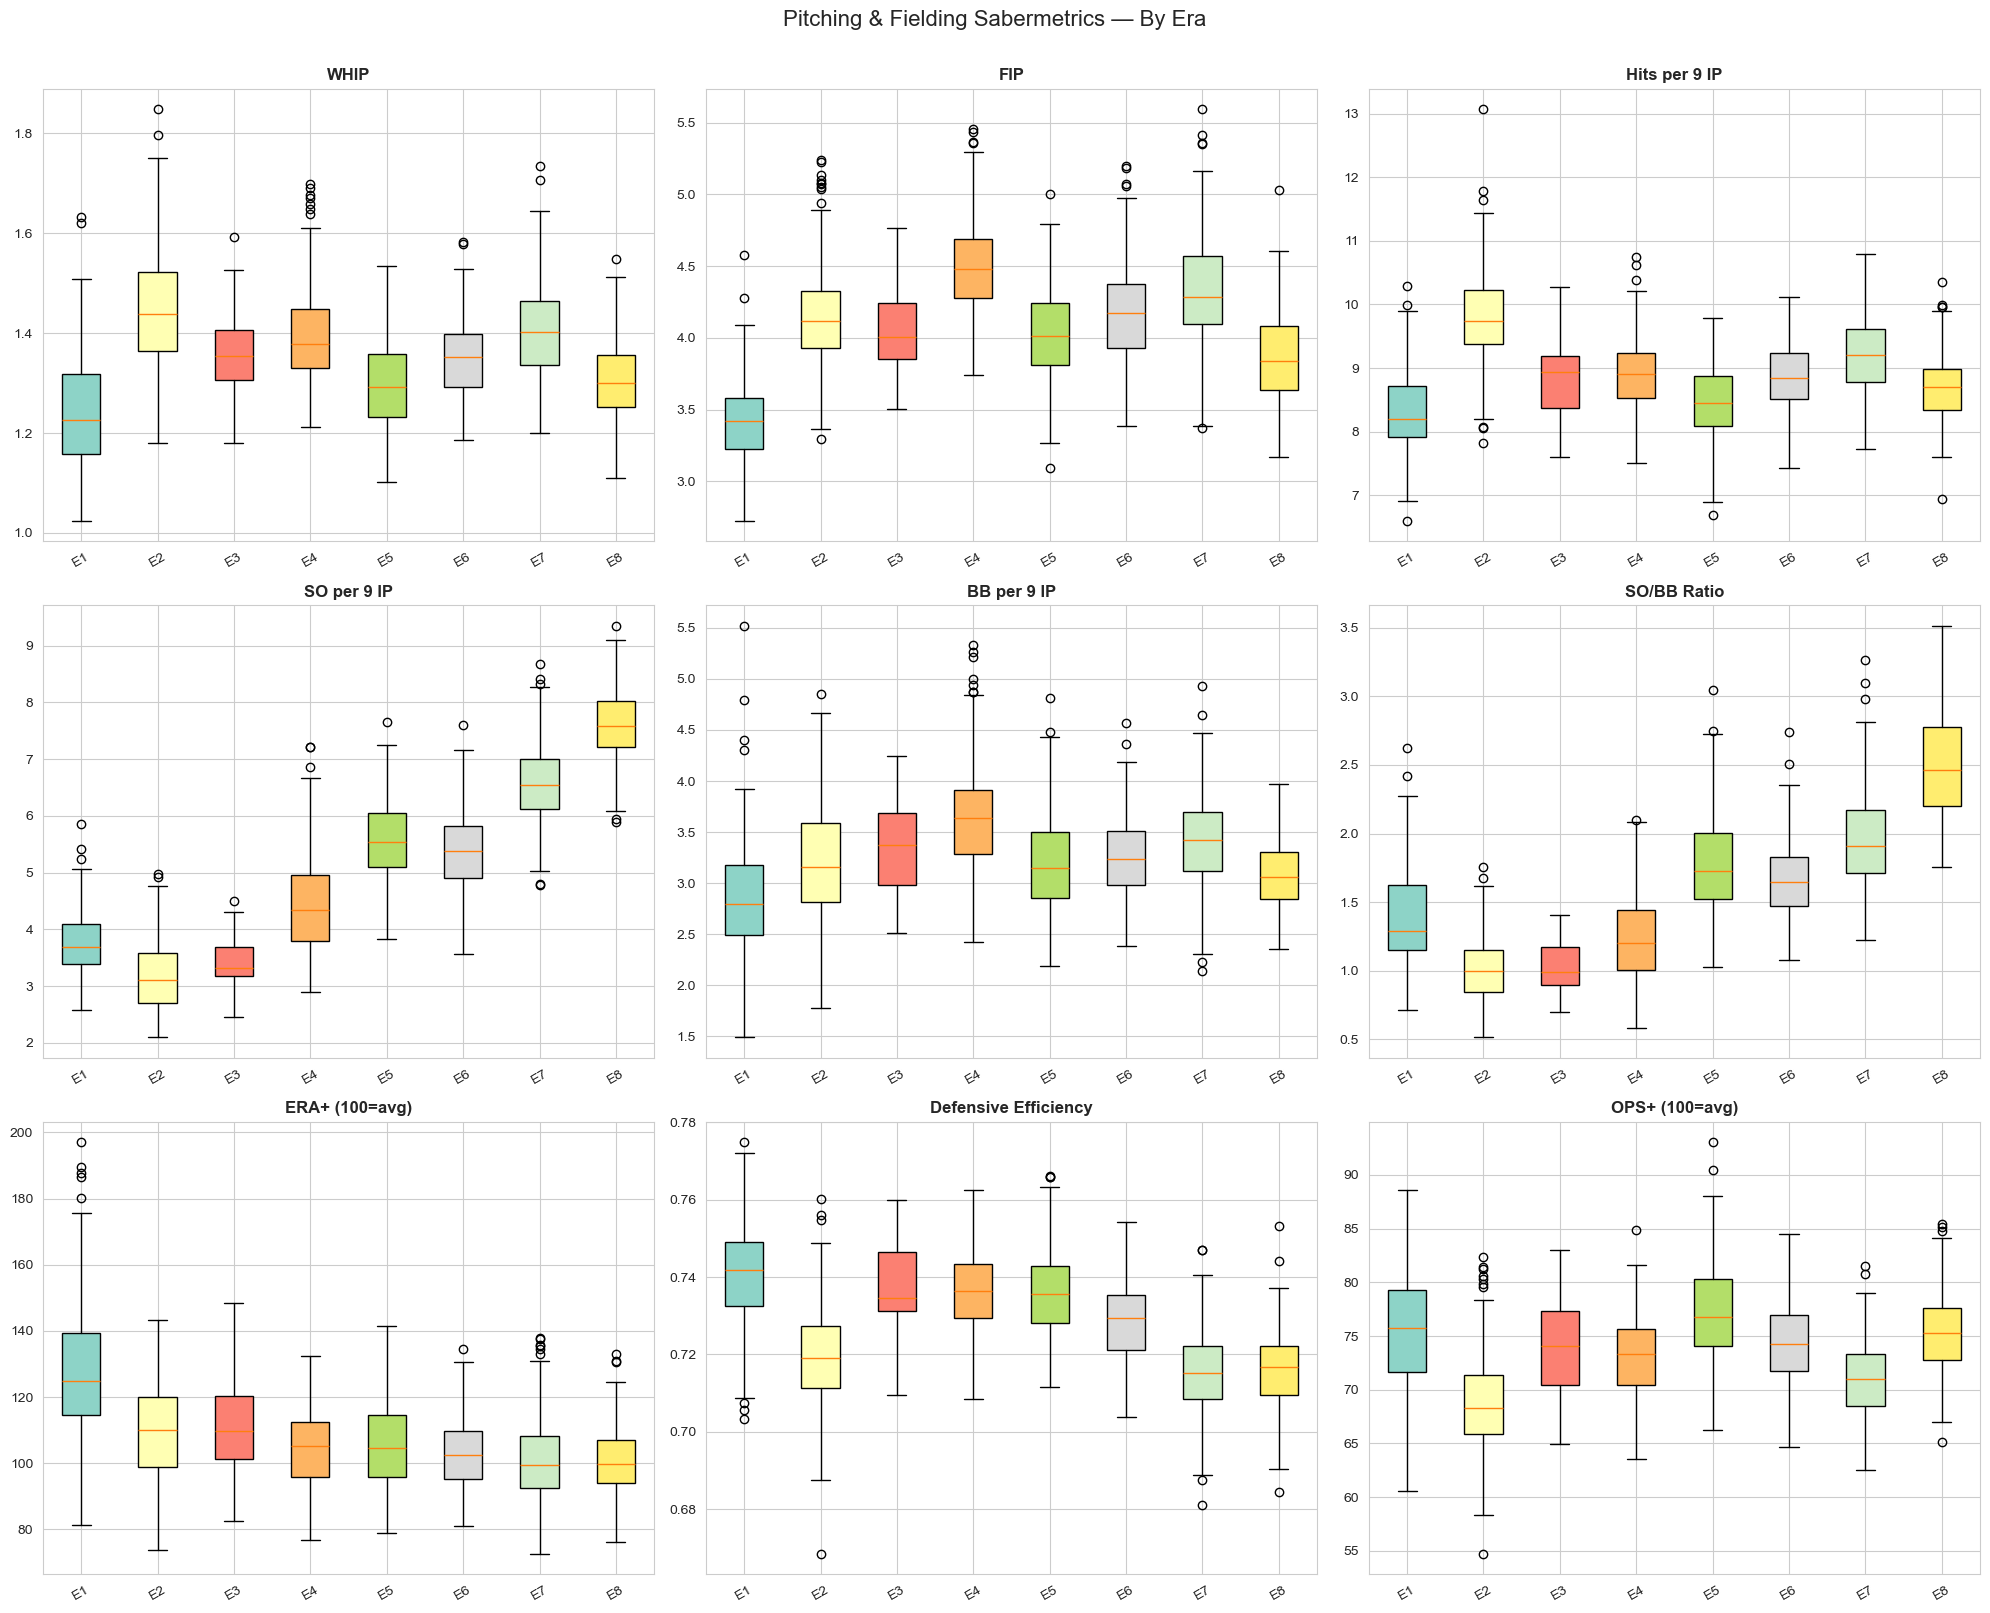

In [13]:
# Pitching sabermetrics by era — 3x3 grid
pitch_saber = ['WHIP', 'FIP', 'H9', 'SO9', 'BB9', 'SO_BB_ratio', 'ERA_plus', 'DER', 'OPS_plus']
pitch_titles = ['WHIP', 'FIP', 'Hits per 9 IP', 'SO per 9 IP', 'BB per 9 IP',
                'SO/BB Ratio', 'ERA+ (100=avg)', 'Defensive Efficiency', 'OPS+ (100=avg)']

fig, axes = plt.subplots(3, 3, figsize=(20, 16))
axes = axes.flatten()

for i, (stat, title) in enumerate(zip(pitch_saber, pitch_titles)):
    data = [train[train['era_label']==e][stat].dropna().values for e in era_order]
    bp = axes[i].boxplot(data, labels=[e.replace('Era ', 'E') for e in era_order], patch_artist=True)
    for patch, c in zip(bp['boxes'], saber_colors):
        patch.set_facecolor(c)
    axes[i].set_title(title, fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=30)

plt.suptitle('Pitching & Fielding Sabermetrics — By Era', fontsize=16, y=1.005)
plt.tight_layout()
plt.show()

### Sabermetric Feature Insights by Era

**Batting:**
- **BA**: Dead ball era had lowest averages (~.250), steroid era highest (~.270)
- **OPS**: Mirrors run environment — lowest in dead ball (~.660), highest in steroid era (~.770)
- **ISO (Isolated Power)**: Steady increase as HR became central; dead ball ~.060, modern ~.160
- **wOBA**: Tracks OPS closely — captures overall offensive contribution
- **K%**: Relentless increase — from ~8% (dead ball) to ~20%+ (modern). The biggest single trend in baseball
- **BB%**: Relatively stable at ~8-10%, slight decline in modern era

**Pitching:**
- **WHIP**: Surprisingly stable across eras (~1.2-1.4) — pitchers adjusted to each era's environment
- **FIP**: More variation than WHIP — lower in pitching-dominant eras, higher in offensive eras
- **SO/9**: Mirrors batting K% — from ~3 to ~8. Pitchers throw harder and more sliders
- **SO/BB Ratio**: Dramatic improvement in modern era (~2.5+) — pitchers are more efficient than ever
- **ERA+/OPS+**: By design, should cluster around 100 in each era — but variance differs

**Run Production:**
- **Run diff/game**: Symmetric around 0 across all eras (as expected — wins are zero-sum within a league)
- **Pythagorean %**: Stable spread around 0.5 — the fundamental win prediction relationship holds across all eras


### 5.6 Violin Plots — Feature Shape by Era

Violin plots show the full distribution shape, not just quartiles. Useful for spotting bimodality or skew.


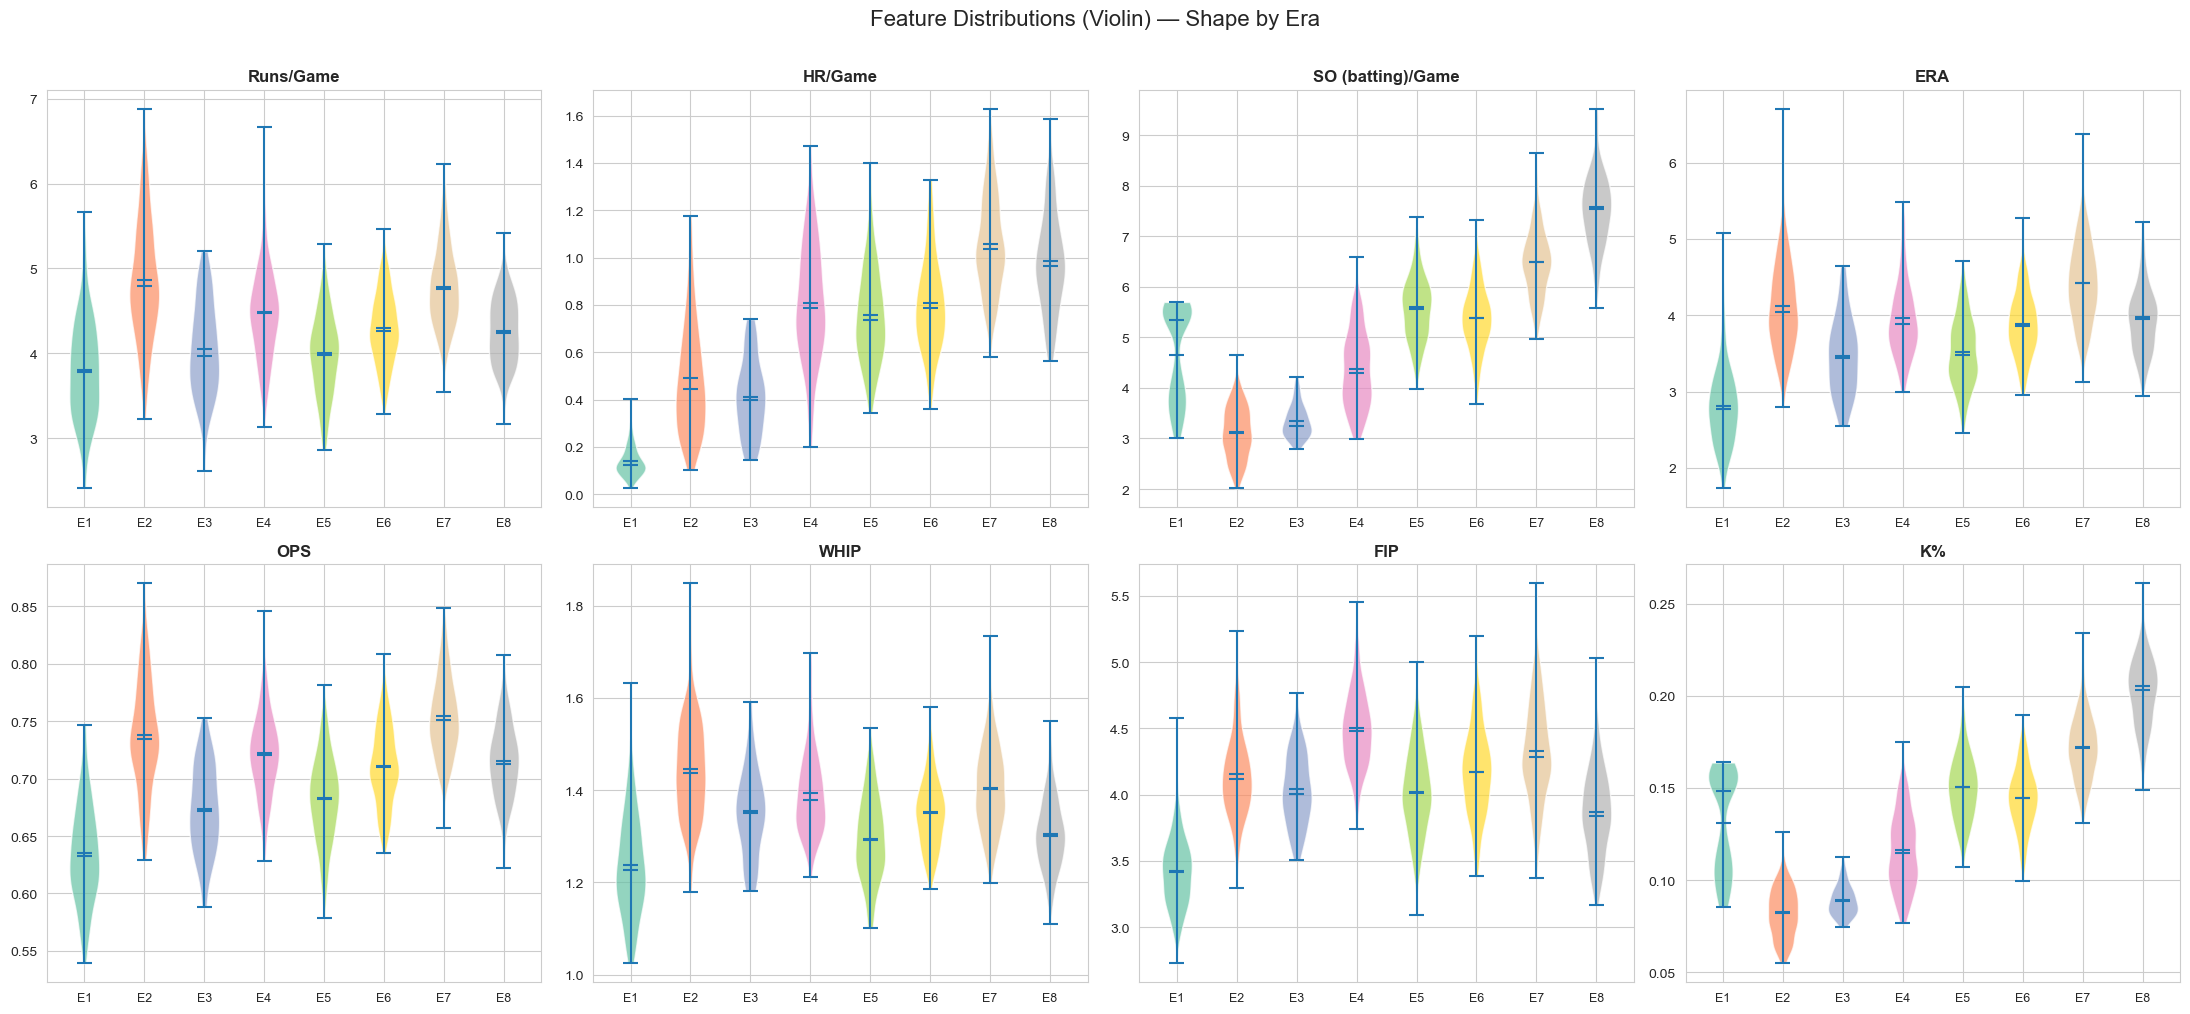

In [14]:
# Violin plots for key features — shows distribution shape
violin_feats = ['R_pg', 'HR_pg', 'SO_pg', 'ERA', 'OPS', 'WHIP', 'FIP', 'K_pct']
violin_titles = ['Runs/Game', 'HR/Game', 'SO (batting)/Game', 'ERA', 'OPS', 'WHIP', 'FIP', 'K%']

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()
era_labels_short = [e.replace('Era ', 'E') for e in era_order]

for i, (stat, title) in enumerate(zip(violin_feats, violin_titles)):
    era_data = []
    era_names = []
    for e in era_order:
        vals = train[train['era_label']==e][stat].dropna().values
        if len(vals) > 5:
            era_data.append(vals)
            era_names.append(e.replace('Era ', 'E'))

    parts = axes[i].violinplot(era_data, showmeans=True, showmedians=True)
    for j, pc in enumerate(parts['bodies']):
        pc.set_facecolor(era_colors[j % len(era_colors)])
        pc.set_alpha(0.7)
    axes[i].set_xticks(range(1, len(era_names)+1))
    axes[i].set_xticklabels(era_names, fontsize=9)
    axes[i].set_title(title, fontsize=12, fontweight='bold')

plt.suptitle('Feature Distributions (Violin) — Shape by Era', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

### 5.7 Era Summary Statistics Table

Numeric summary of all key features by era — means with standard deviations.


In [15]:
# Era summary table
summary_stats = ['R_pg', 'HR_pg', 'H_pg', 'SO_pg', 'BB_pg', 'SB_pg',
                 'ERA', 'HA_pg', 'SOA_pg', 'CG_pg', 'SV_pg', 'E',
                 'BA', 'OPS', 'WHIP', 'FIP', 'K_pct', 'BB_pct']

era_summary = train.groupby('era_label')[summary_stats].agg(['mean', 'std'])

# Format nicely
print("ERA SUMMARY — Feature Means (± Std) Across Eras")
print("=" * 120)
for stat in summary_stats:
    row = f"{stat:12s}"
    for era in era_order:
        if era in era_summary.index:
            m = era_summary.loc[era, (stat, 'mean')]
            s = era_summary.loc[era, (stat, 'std')]
            row += f"  {m:7.3f}±{s:.3f}"
        else:
            row += f"  {'N/A':>13}"
    print(row)
print("=" * 120)
print(f"{'':12s}", end='')
for era in era_order:
    n = (train['era_label']==era).sum()
    print(f"  {era.replace('Era ','E'):>6s}(n={n})", end='')
print()

ERA SUMMARY — Feature Means (± Std) Across Eras
R_pg            3.808±0.608    4.861±0.725    4.053±0.564    4.470±0.555    3.981±0.495    4.296±0.432    4.785±0.489    4.267±0.423
HR_pg           0.140±0.065    0.489±0.233    0.411±0.163    0.808±0.251    0.756±0.202    0.807±0.202    1.059±0.206    0.984±0.214
H_pg            8.231±0.594    9.740±0.614    8.785±0.446    8.872±0.436    8.445±0.565    8.812±0.460    9.140±0.462    8.649±0.472
SO_pg           4.654±0.928    3.123±0.529    3.351±0.331    4.376±0.764    5.562±0.642    5.376±0.648    6.493±0.671    7.535±0.732
BB_pg           2.751±0.505    3.168±0.596    3.319±0.394    3.605±0.543    3.182±0.445    3.241±0.384    3.387±0.457    3.031±0.360
SB_pg           1.203±0.313    0.490±0.201    0.399±0.196    0.322±0.145    0.504±0.246    0.759±0.278    0.624±0.214    0.580±0.194
ERA             2.811±0.532    4.127±0.608    3.469±0.517    3.959±0.509    3.519±0.461    3.882±0.422    4.428±0.533    3.949±0.446
HA_pg           8.228

## 6. Games Played (G) — The Normalisation Confound

A key reason to normalise by G: season length varied across history.


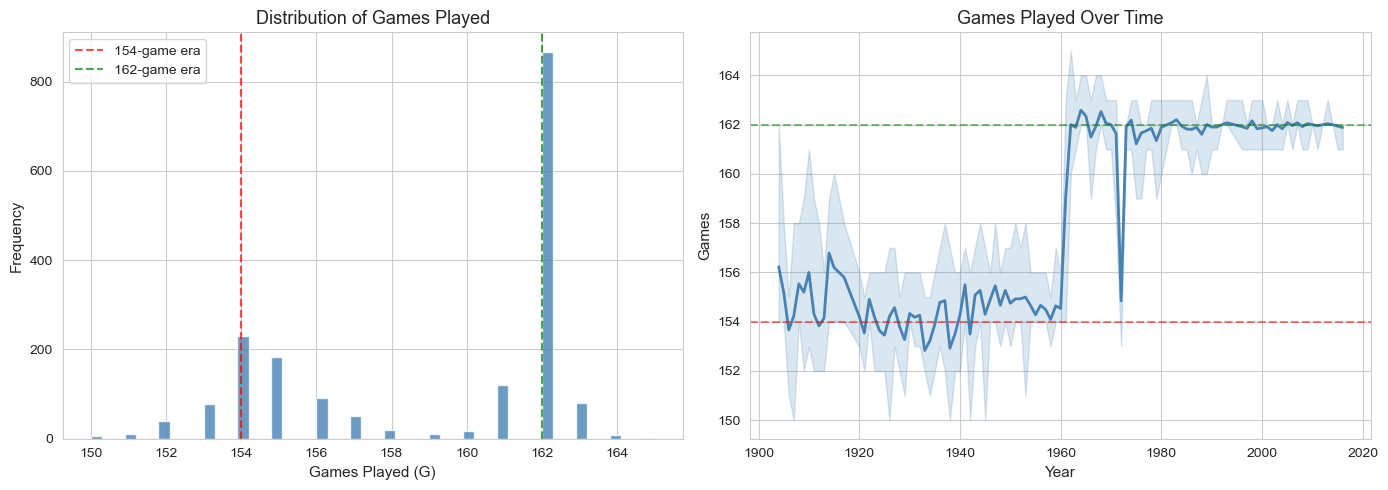

G range: 150 - 165
G < 154: 134 team-seasons (7.4%)
G = 154: 229 team-seasons
G = 162: 867 team-seasons


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# G distribution
axes[0].hist(train['G'], bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_xlabel('Games Played (G)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Games Played')
axes[0].axvline(154, color='red', ls='--', alpha=0.7, label='154-game era')
axes[0].axvline(162, color='green', ls='--', alpha=0.7, label='162-game era')
axes[0].legend()

# G over time
yearly_g = train.groupby('yearID')['G'].agg(['mean', 'min', 'max'])
axes[1].fill_between(yearly_g.index, yearly_g['min'], yearly_g['max'], alpha=0.2, color='steelblue')
axes[1].plot(yearly_g.index, yearly_g['mean'], color='steelblue', lw=2)
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Games')
axes[1].set_title('Games Played Over Time')
axes[1].axhline(154, color='red', ls='--', alpha=0.5)
axes[1].axhline(162, color='green', ls='--', alpha=0.5)

plt.tight_layout()
plt.show()

print(f"G range: {train['G'].min()} - {train['G'].max()}")
print(f"G < 154: {(train['G'] < 154).sum()} team-seasons ({(train['G'] < 154).mean()*100:.1f}%)")
print(f"G = 154: {(train['G'] == 154).sum()} team-seasons")
print(f"G = 162: {(train['G'] == 162).sum()} team-seasons")

## 7. Correlation Analysis

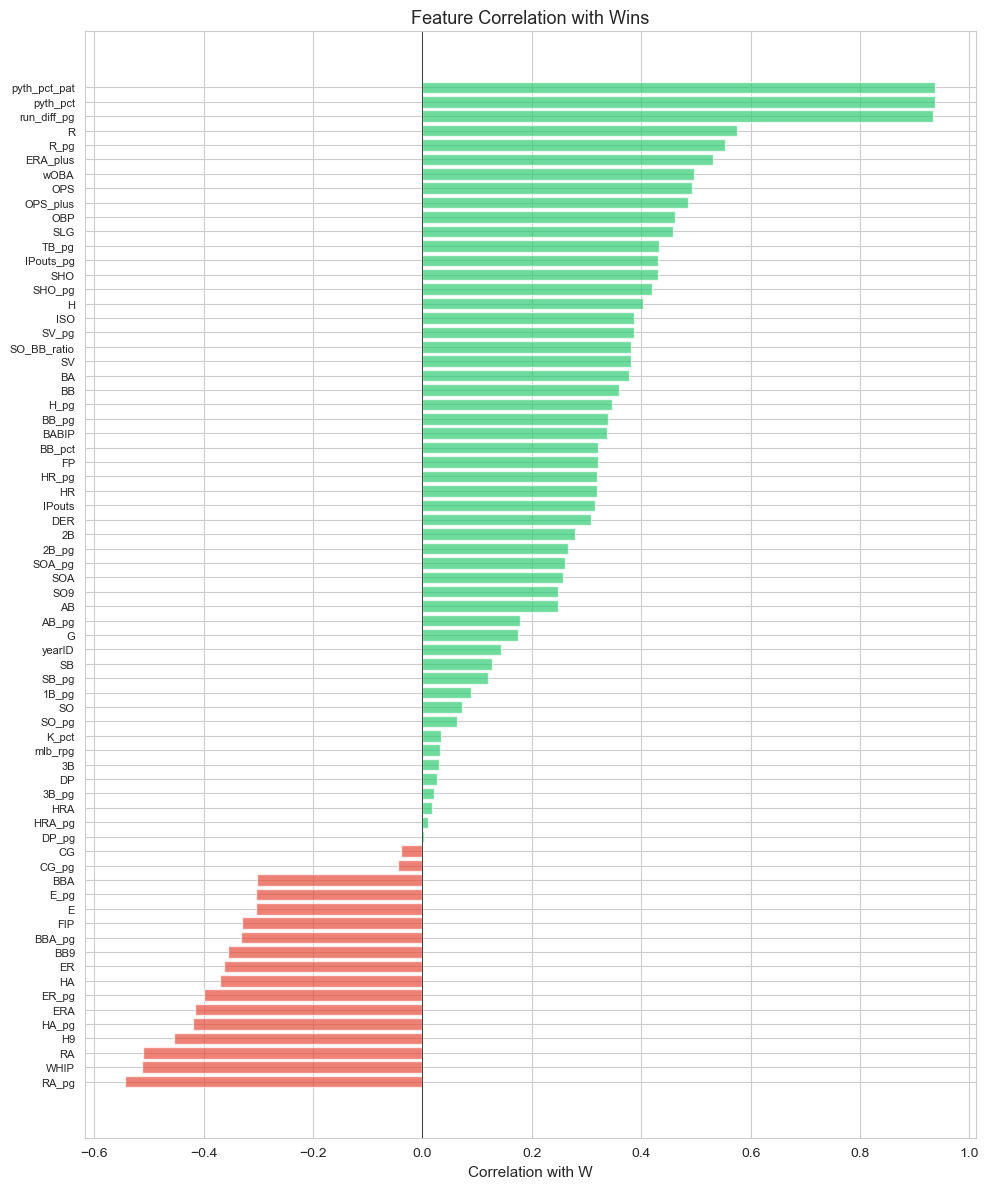


Top 10 positive correlations with W:
  pyth_pct_pat          +0.938
  pyth_pct              +0.937
  run_diff_pg           +0.934
  R                     +0.575
  R_pg                  +0.552
  ERA_plus              +0.532
  wOBA                  +0.497
  OPS                   +0.492
  OPS_plus              +0.486
  OBP                   +0.462

Top 10 negative correlations with W:
  BB9                   -0.355
  ER                    -0.363
  HA                    -0.370
  ER_pg                 -0.399
  ERA                   -0.416
  HA_pg                 -0.419
  H9                    -0.454
  RA                    -0.511
  WHIP                  -0.512
  RA_pg                 -0.543


In [17]:
# Correlation with W (target)
numeric_cols = train.select_dtypes(include=[np.number]).columns.tolist()
skip = ['ID', 'year_label', 'win_bins'] + [c for c in numeric_cols if c.startswith(('era_', 'decade_'))]
use_cols = [c for c in numeric_cols if c not in skip and c != 'W']

corr_with_w = train[use_cols + ['W']].corr()['W'].drop('W').sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 12))
colors = ['#2ecc71' if v > 0 else '#e74c3c' for v in corr_with_w]
ax.barh(range(len(corr_with_w)), corr_with_w.values, color=colors, alpha=0.7)
ax.set_yticks(range(len(corr_with_w)))
ax.set_yticklabels(corr_with_w.index, fontsize=8)
ax.set_xlabel('Correlation with W')
ax.set_title('Feature Correlation with Wins')
ax.axvline(0, color='black', lw=0.5)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print("\nTop 10 positive correlations with W:")
for feat, corr in corr_with_w.head(10).items():
    print(f"  {feat:20s}  {corr:+.3f}")

print("\nTop 10 negative correlations with W:")
for feat, corr in corr_with_w.tail(10).items():
    print(f"  {feat:20s}  {corr:+.3f}")

### 7.1 Multicollinearity Heatmap — Top Correlated Features

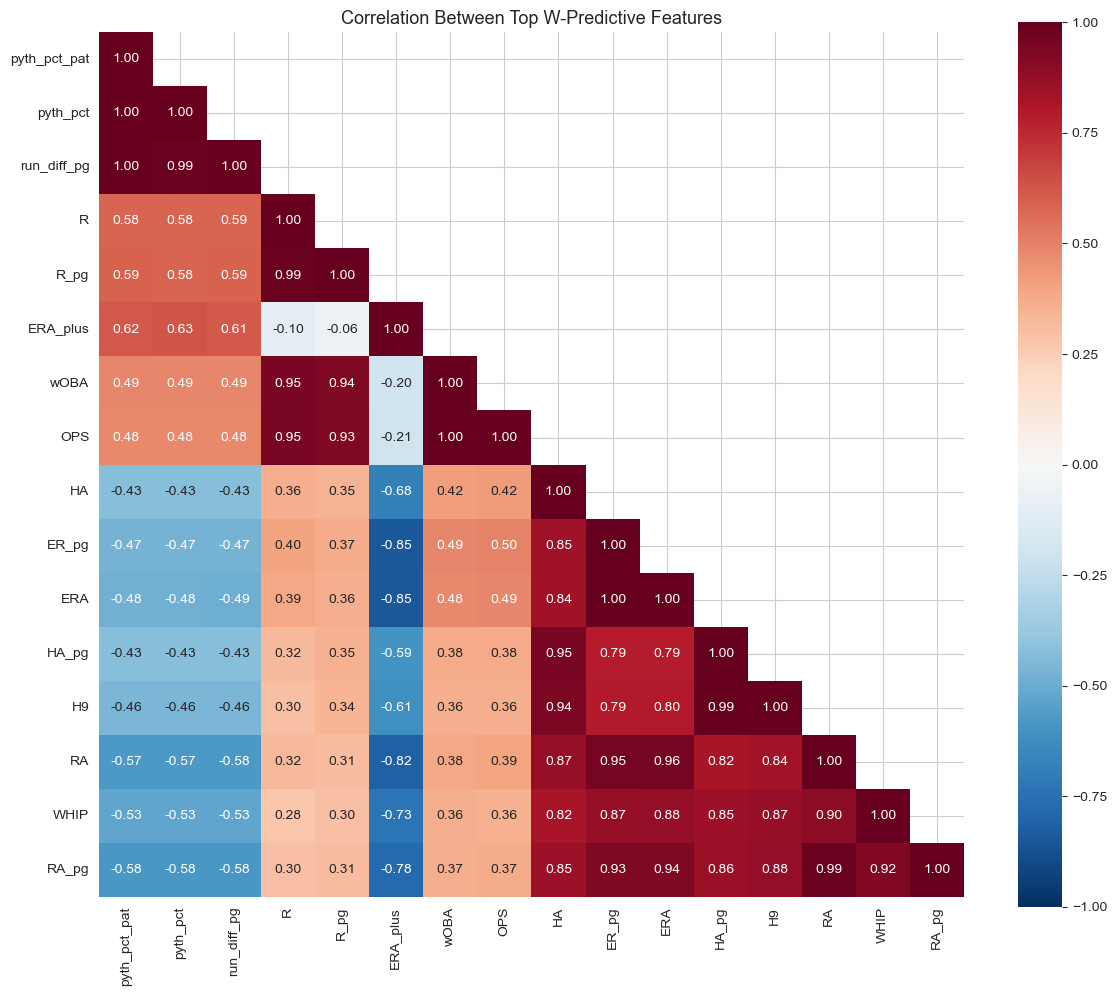

In [18]:
# Heatmap of top features most correlated with W
top_feats = list(corr_with_w.head(8).index) + list(corr_with_w.tail(8).index)
corr_matrix = train[top_feats].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title('Correlation Between Top W-Predictive Features')
plt.tight_layout()
plt.show()

## 8. Key Relationships with Wins

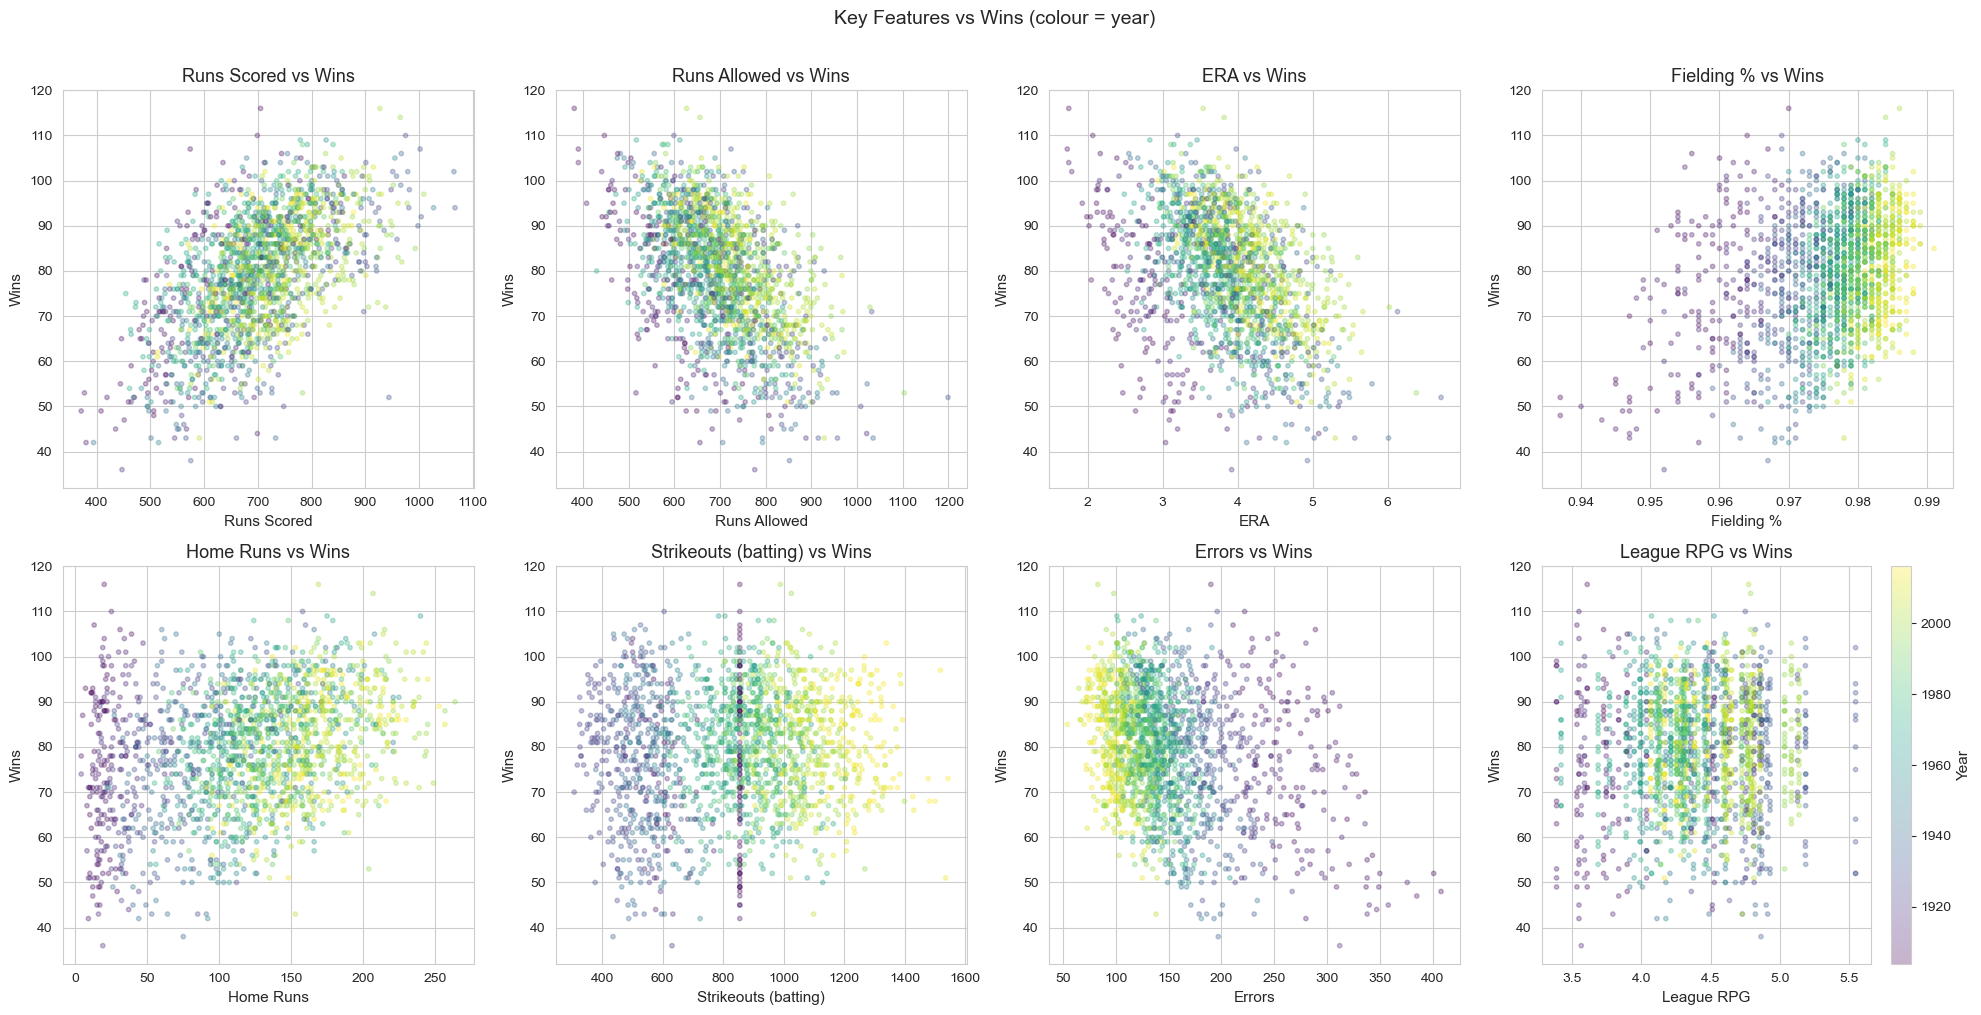

In [19]:
# Scatter plots of key predictors vs W
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
key_feats = ['R', 'RA', 'ERA', 'FP', 'HR', 'SO', 'E', 'mlb_rpg']
titles = ['Runs Scored', 'Runs Allowed', 'ERA', 'Fielding %',
          'Home Runs', 'Strikeouts (batting)', 'Errors', 'League RPG']

for i, (feat, title) in enumerate(zip(key_feats, titles)):
    ax = axes[i//4][i%4]
    scatter = ax.scatter(train[feat], train['W'], c=train['yearID'],
                        cmap='viridis', alpha=0.3, s=10)
    ax.set_xlabel(title)
    ax.set_ylabel('Wins')
    ax.set_title(f'{title} vs Wins')

# Add colorbar to last plot
plt.colorbar(scatter, ax=axes[1][3], label='Year')
plt.suptitle('Key Features vs Wins (colour = year)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 9. mlb_rpg — The League Run Environment

`mlb_rpg` (MLB runs per game) captures the overall run environment of each season. This is the most important normalisation variable in the dataset.


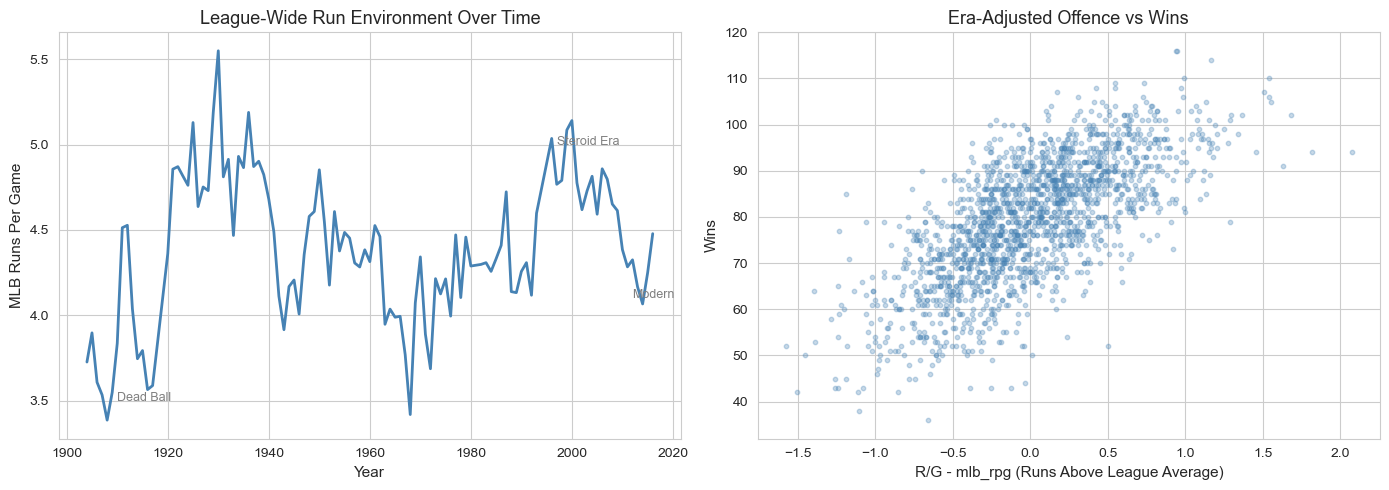

Raw R correlation with W:          0.575
Era-adjusted R/G correlation with W: 0.692


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# mlb_rpg over time
yearly_rpg = train.groupby('yearID')['mlb_rpg'].first()
axes[0].plot(yearly_rpg.index, yearly_rpg.values, color='steelblue', lw=2)
axes[0].set_xlabel('Year')
axes[0].set_ylabel('MLB Runs Per Game')
axes[0].set_title('League-Wide Run Environment Over Time')

# Annotate key periods
axes[0].annotate('Dead Ball', xy=(1910, 3.5), fontsize=9, color='gray')
axes[0].annotate('Steroid Era', xy=(1997, 5.0), fontsize=9, color='gray')
axes[0].annotate('Modern', xy=(2012, 4.1), fontsize=9, color='gray')

# R_per_game relative to mlb_rpg
train['R_relative'] = train['R'] / train['G'] - train['mlb_rpg']
axes[1].scatter(train['R_relative'], train['W'], alpha=0.3, s=10, color='steelblue')
axes[1].set_xlabel('R/G - mlb_rpg (Runs Above League Average)')
axes[1].set_ylabel('Wins')
axes[1].set_title('Era-Adjusted Offence vs Wins')

plt.tight_layout()
plt.show()

# Correlation improvement
raw_corr = train['R'].corr(train['W'])
adj_corr = train['R_relative'].corr(train['W'])
print(f"Raw R correlation with W:          {raw_corr:.3f}")
print(f"Era-adjusted R/G correlation with W: {adj_corr:.3f}")

## 10. Feature Distribution Histograms — By Era

Showing how the same statistic has completely different distributions across eras.


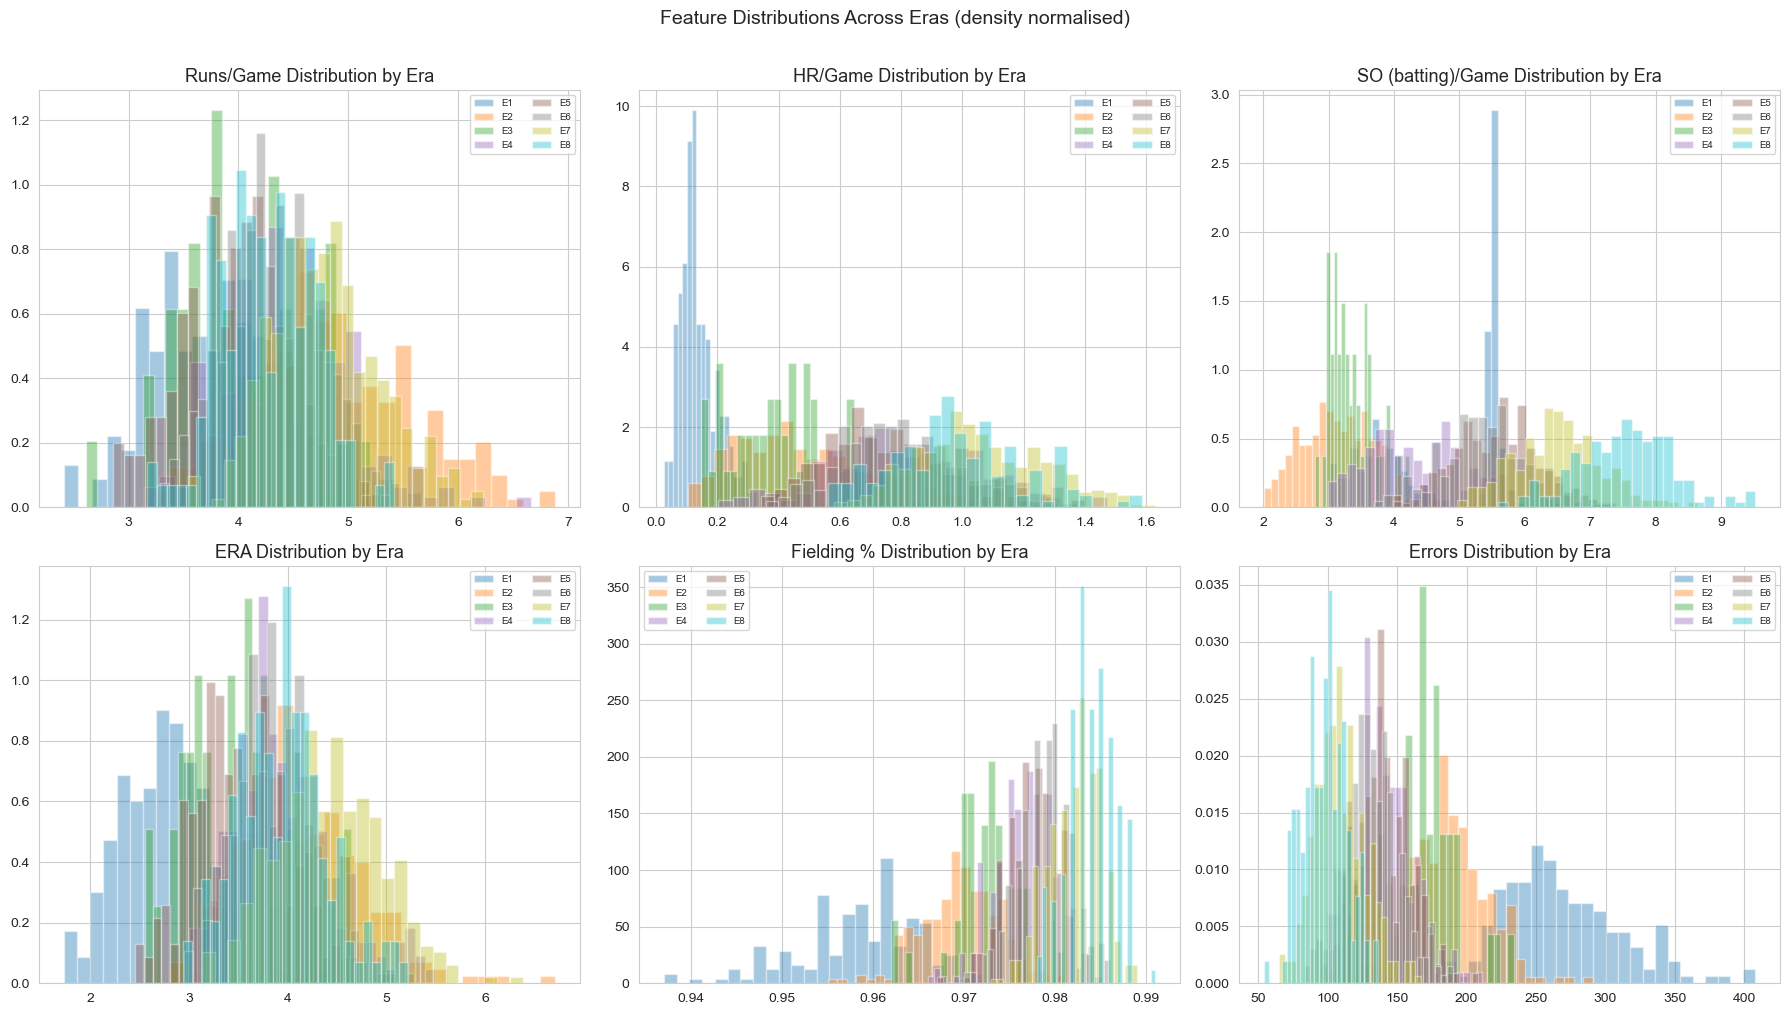

In [21]:
# Distribution overlays by era for key per-game stats
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
stats = ['R_pg', 'HR_pg', 'SO_pg', 'ERA', 'FP', 'E']
titles_dist = ['Runs/Game', 'HR/Game', 'SO (batting)/Game', 'ERA', 'Fielding %', 'Errors']
era_colors = plt.cm.tab10(np.linspace(0, 1, 8))

# Ensure per-game cols exist
if 'E_pg' not in train.columns:
    train['E_pg'] = train['E'] / train['G']
stats_actual = ['R_pg', 'HR_pg', 'SO_pg', 'ERA', 'FP', 'E']

for i, (stat, title) in enumerate(zip(stats_actual, titles_dist)):
    ax = axes[i//3][i%3]
    for j, era in enumerate(era_order):
        subset = train[train['era_label'] == era][stat].dropna()
        if len(subset) > 5:
            ax.hist(subset, bins=25, alpha=0.4, color=era_colors[j],
                   label=era.replace('Era ', 'E'), density=True)
    ax.set_title(f'{title} Distribution by Era')
    ax.legend(fontsize=7, ncol=2)

plt.suptitle('Feature Distributions Across Eras (density normalised)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 11. Normalisation Strategies — Comparison & Recommendations

Based on the EDA above, here are the normalisation approaches that should be considered:

### Strategy 1: Per-Game Normalisation
**What:** Divide all counting stats by G
**Removes:** Season-length confound (154 vs 162 games)
**Limitation:** Does not account for era-level changes in run environment

```python
for stat in counting_stats:
    df[f'{stat}_pg'] = df[stat] / df['G']
```

### Strategy 2: Z-Score Within Year
**What:** For each yearID, standardise each feature to mean=0, std=1
**Removes:** All year-to-year variation — features become "how far above/below that year's average"
**Risk:** Loses absolute level information; small-sample years have noisy z-scores

```python
df[f'{stat}_zscore'] = df.groupby('yearID')[stat].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-6)
)
```

### Strategy 3: Relative to League Average (mlb_rpg-based)
**What:** Express stats relative to the league's run environment
**Removes:** Era-level scoring environment differences
**Example:** ERA+ = (league_ERA / team_ERA) × 100

```python
df['R_vs_mlb'] = df['R'] / df['G'] - df['mlb_rpg']
df['ERA_plus'] = (df['mlb_rpg'] * 0.92) / df['ERA'] * 100
```

### Strategy 4: Decade/Era Grouping
**What:** Z-score or percentile within era/decade groups
**Removes:** Broad era effects with larger sample sizes than per-year
**Advantage:** More stable than per-year z-scores

```python
df[f'{stat}_era_z'] = df.groupby('era_label')[stat].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-6)
)
```

### Recommendation for Ridge Regression
| Strategy | Pros | Cons | Verdict |
|---|---|---|---|
| Per-game (÷G) | Simple, removes game count bias | Doesn't fix era shifts | **Use as baseline** |
| Z-score within year | Removes all era effects | Loses absolute levels, noisy for small N | Test carefully |
| mlb_rpg-relative | Domain-grounded, already in data | Only adjusts offence/pitching, not fielding | **Best for run stats** |
| Era z-score | Larger groups, more stable | Boundaries are arbitrary | Good middle ground |
| **Combined** | Per-game + mlb_rpg relative | Slightly more features | **Recommended** |

The best approach is likely **per-game normalisation (÷G) combined with mlb_rpg-relative adjustments** — this is what `model_v5.py` implements.


### 11.1 Visualise Normalisation Impact

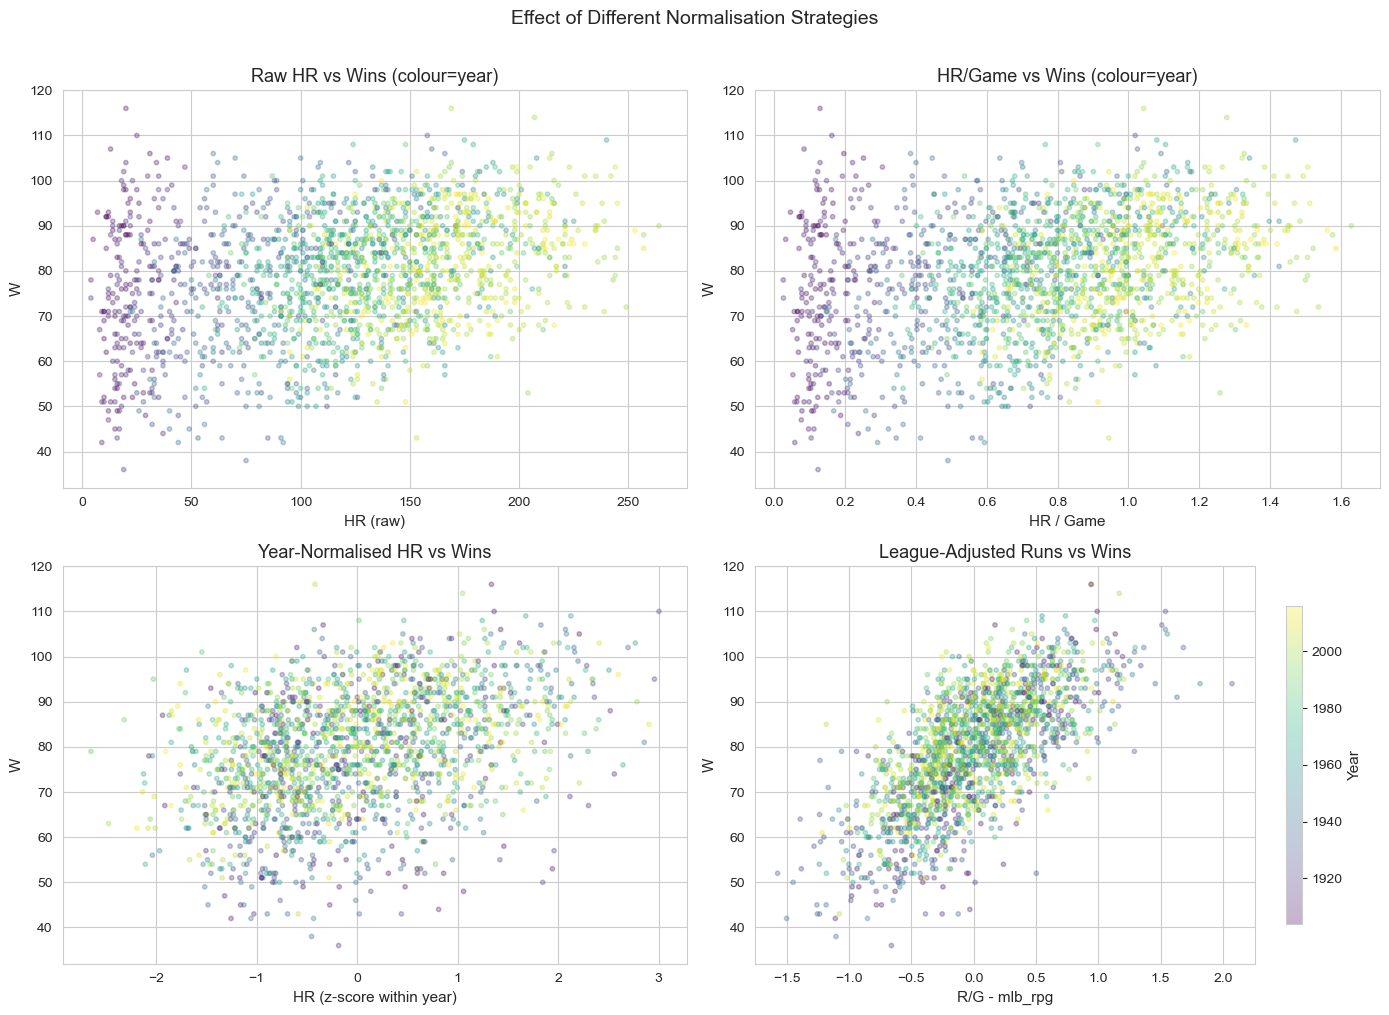

Correlation with W under different normalisations:
  Raw HR:                +0.318
  HR/Game:               +0.319
  HR z-score (per year): +0.381
  R/G - mlb_rpg:         +0.692


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Raw HR vs W — confounded by era
axes[0][0].scatter(train['HR'], train['W'], c=train['yearID'], cmap='viridis', alpha=0.3, s=10)
axes[0][0].set_xlabel('HR (raw)')
axes[0][0].set_ylabel('W')
axes[0][0].set_title('Raw HR vs Wins (colour=year)')

# HR per game vs W — removes G confound
axes[0][1].scatter(train['HR_pg'], train['W'], c=train['yearID'], cmap='viridis', alpha=0.3, s=10)
axes[0][1].set_xlabel('HR / Game')
axes[0][1].set_ylabel('W')
axes[0][1].set_title('HR/Game vs Wins (colour=year)')

# Z-score HR within year vs W — removes era entirely
train['HR_zscore'] = train.groupby('yearID')['HR'].transform(lambda x: (x - x.mean()) / (x.std() + 1e-6))
axes[1][0].scatter(train['HR_zscore'], train['W'], c=train['yearID'], cmap='viridis', alpha=0.3, s=10)
axes[1][0].set_xlabel('HR (z-score within year)')
axes[1][0].set_ylabel('W')
axes[1][0].set_title('Year-Normalised HR vs Wins')

# R relative to league vs W — mlb_rpg adjustment
scatter = axes[1][1].scatter(train['R_relative'], train['W'], c=train['yearID'], cmap='viridis', alpha=0.3, s=10)
axes[1][1].set_xlabel('R/G - mlb_rpg')
axes[1][1].set_ylabel('W')
axes[1][1].set_title('League-Adjusted Runs vs Wins')

plt.colorbar(scatter, ax=axes[1][1], label='Year', shrink=0.8)
plt.suptitle('Effect of Different Normalisation Strategies', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Correlation comparison
print("Correlation with W under different normalisations:")
print(f"  Raw HR:                {train['HR'].corr(train['W']):+.3f}")
print(f"  HR/Game:               {train['HR_pg'].corr(train['W']):+.3f}")
print(f"  HR z-score (per year): {train['HR_zscore'].corr(train['W']):+.3f}")
print(f"  R/G - mlb_rpg:         {train['R_relative'].corr(train['W']):+.3f}")

## 12. Train vs Test Distribution Check

Important for detecting potential distribution shift that causes the CV-to-public gap.


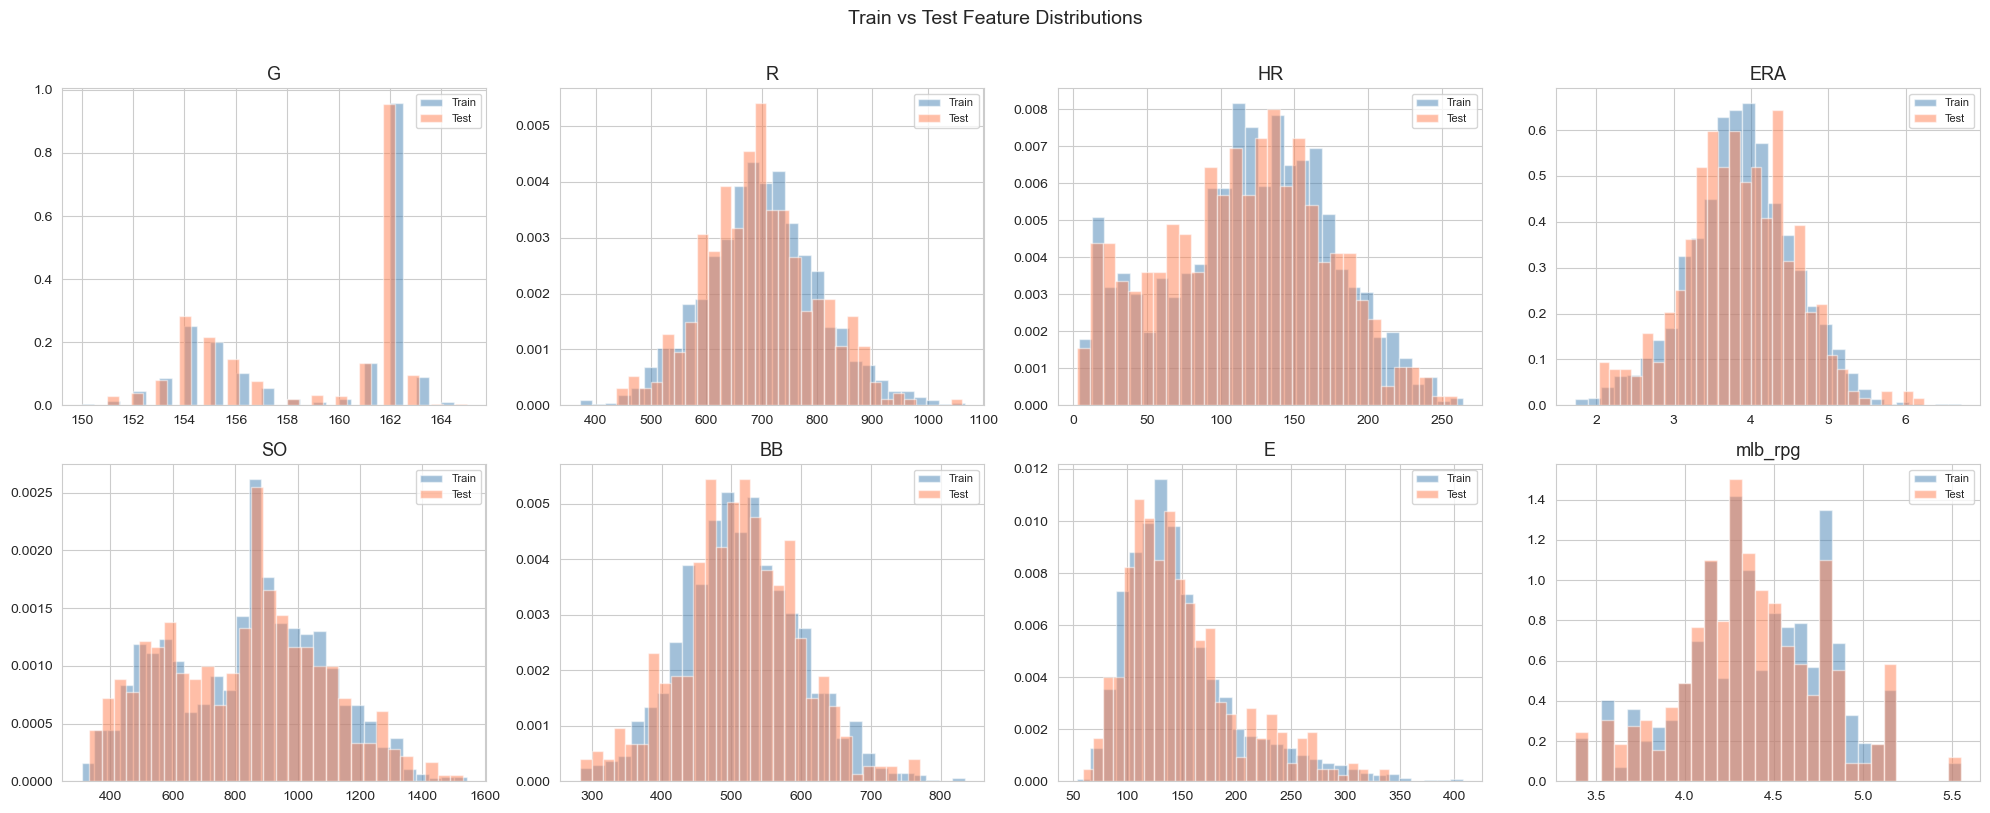

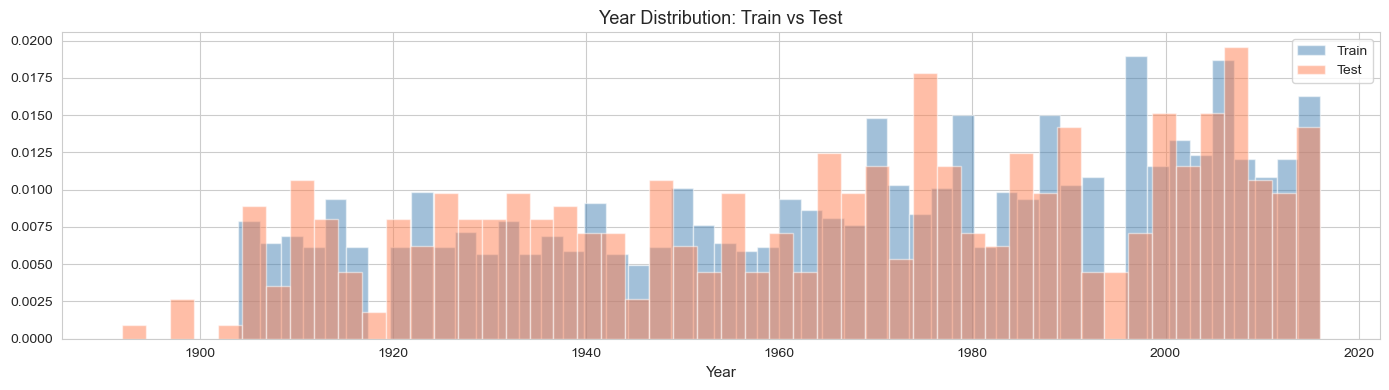

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
compare_stats = ['G', 'R', 'HR', 'ERA', 'SO', 'BB', 'E', 'mlb_rpg']

for i, stat in enumerate(compare_stats):
    ax = axes[i//4][i%4]
    ax.hist(train[stat], bins=30, alpha=0.5, density=True, color='steelblue', label='Train')
    ax.hist(test[stat], bins=30, alpha=0.5, density=True, color='coral', label='Test')
    ax.set_title(stat)
    ax.legend(fontsize=8)

plt.suptitle('Train vs Test Feature Distributions', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Year distribution comparison
fig, ax = plt.subplots(figsize=(14, 4))
ax.hist(train['yearID'], bins=50, alpha=0.5, color='steelblue', label='Train', density=True)
ax.hist(test['yearID'], bins=50, alpha=0.5, color='coral', label='Test', density=True)
ax.set_xlabel('Year')
ax.set_title('Year Distribution: Train vs Test')
ax.legend()
plt.tight_layout()
plt.show()

## 13. Summary of EDA Findings

### Data Characteristics
1. **1,812 train / 453 test** team-seasons spanning 1892-2016
2. **No missing values** in the original features
3. **High multicollinearity** — many features are mathematically related (FP↔E: r=0.996, ERA↔ER: r=0.988)
4. **W is approximately normal** — mean 79, std 13, range [36, 116]

### Era Effects
- Raw counting stats vary **dramatically** across eras (HR: 0 → 250, SO: 300 → 1200, CG: 100 → 2)
- Rate stats (ERA, FP) are more stable but still era-dependent
- `mlb_rpg` captures the run environment and is the best normalisation anchor

### Normalisation Recommendations
1. **Always divide counting stats by G** — removes season-length confound
2. **Use mlb_rpg-relative features** for offence/pitching (ERA+, OPS+, R_vs_mlb)
3. **Consider year-level z-scoring** as an additional normalisation layer
4. **StandardScaler before Ridge** remains necessary for regularisation to work fairly

### Modelling Implications
- **Pythagorean wins** are the strongest single predictor family
- **Ridge handles multicollinearity gracefully** — no need to drop correlated features
- **More features + regularisation > fewer features** for this dataset
- **Era indicators** (era_1..era_8) help capture residual era effects not captured by mlb_rpg
